# TP 3: Stabilise, then transform each token

In TP2, my attention head mixed positions using content-dependent weights. Here I ask how I can transform each token without mixing positions, and what normalisation and residual connections actually preserve.

I build LayerNorm and a feed-forward network, then examine their combination with a residual addition. I use small calculations and controlled changes to separate what the formulas guarantee from what I observe at initialisation.

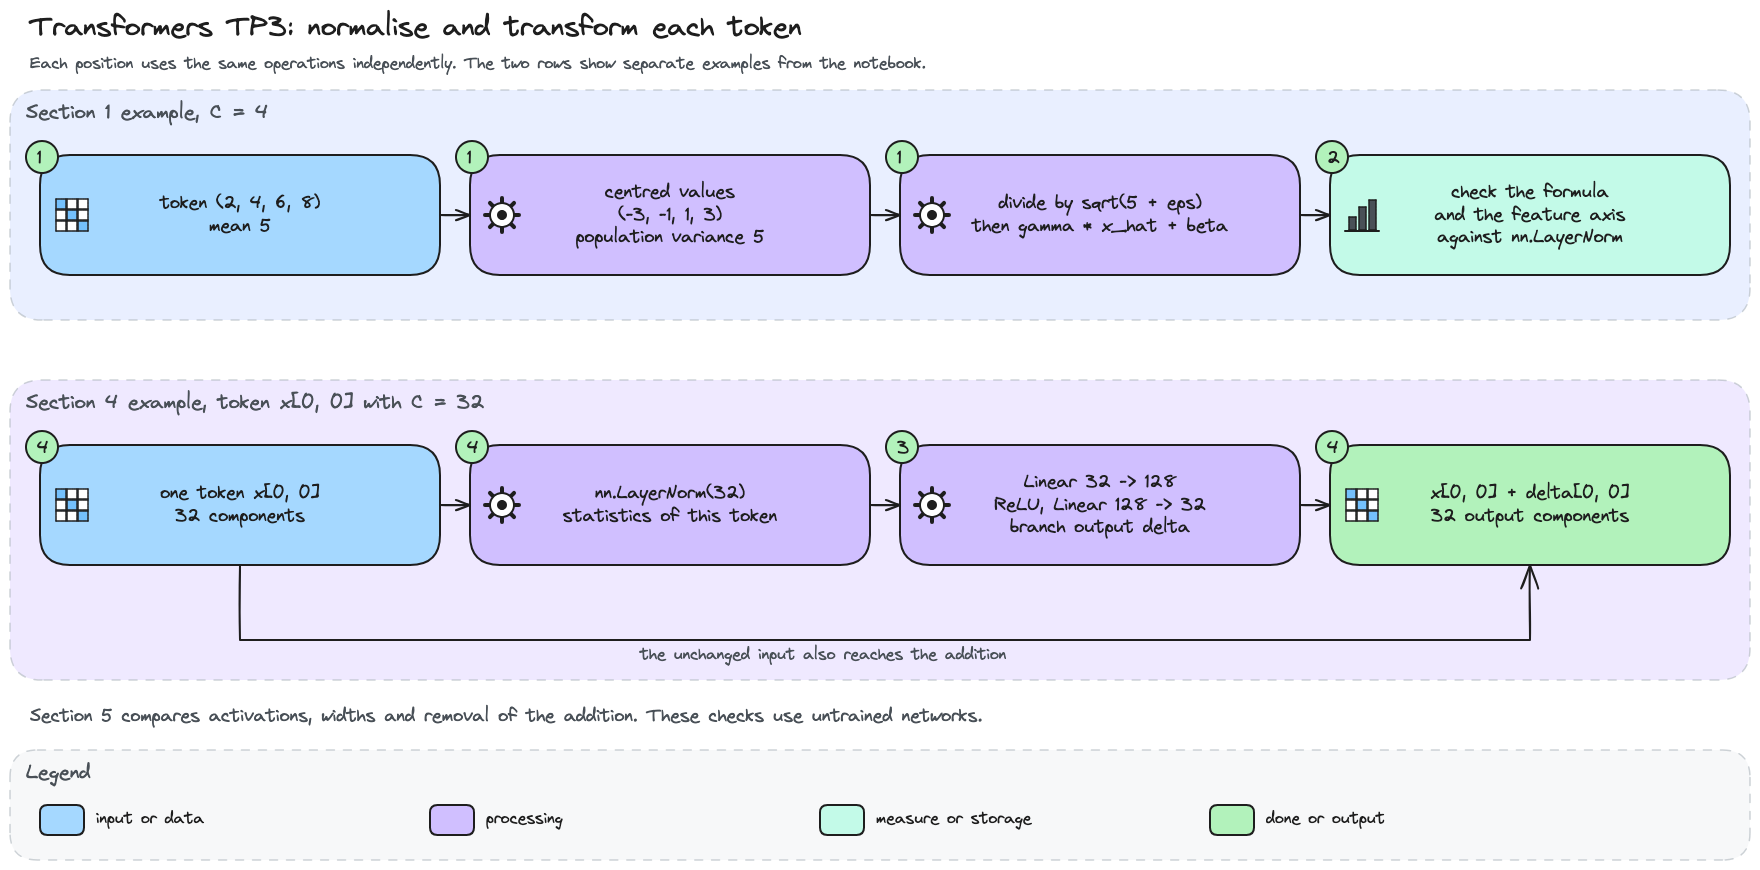

In [1]:
# Workflow diagram: one token through LayerNorm, the feed-forward network and the residual.
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp3_workflow.png', width=900))

## 0. My problem and what I carry over

TP2 showed how score scale affected softmax concentration and local sensitivity in my examples. It did not measure learning, so I carry over the habit of checking numerical behaviour before claiming that a mechanism helps training.

For TP3, I need to understand which values each operation uses and what changes when I alter one input. I begin with normalisation, then study the feed-forward transformation and the residual path.

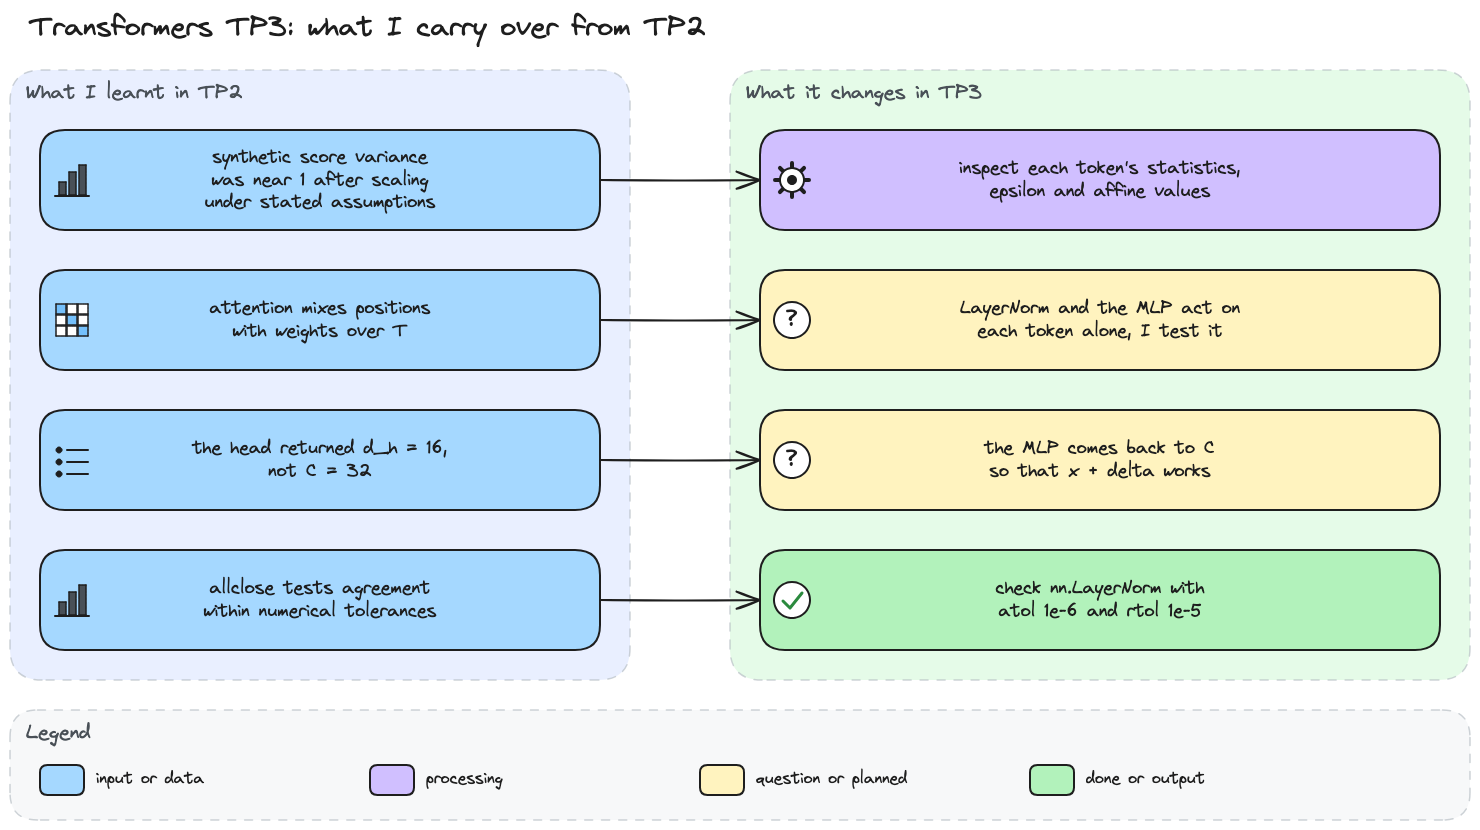

In [2]:
# What I carry over from TP2 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp3_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - My LayerNorm gives every token a mean of 0 and a standard deviation of 1 over its C components, whatever its scale or shift. Section 1 checks it.
> - On a batch of 32 tokens, the features of one token come out near (0, 1), while one feature across the 32 tokens gets no imposed value. I test both lines in section 2.
> - About half of the ReLU activations are positive, because the first linear layer gives values centred on 0.
> - The feed-forward network acts on each token alone, so changing one token changes only its own output. Section 3 counts the activations and tests this.
> - In the pre-norm block, x_out stays close to x, because delta is small at initialisation. I measure it in section 4.
> - The parameters of the feed-forward network grow linearly with its expansion factor, and removing the residual keeps the shape (B, T, C). Section 5 counts and compares.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in TP1 and TP2.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I keep these small synthetic experiments on the CPU. Seed 42 sets the initial random state, while individual experiments reset their stated seeds to make their draws reproducible in this environment.

No optimiser updates any weights in this notebook. Some cells calculate gradients, which lets me inspect sensitivity without training a model.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the initial examples set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: CPU, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: CPU, seed: 42


## 1. Code LayerNorm

I want to control the spread within a token while keeping its output independent of other tokens. LayerNorm uses the token's own mean and variance, which makes the choice of axis part of the mechanism.

I start with an explicit formula so I can inspect epsilon, gamma and beta separately. The first examples keep that formula fixed and change the input's scale or shift.

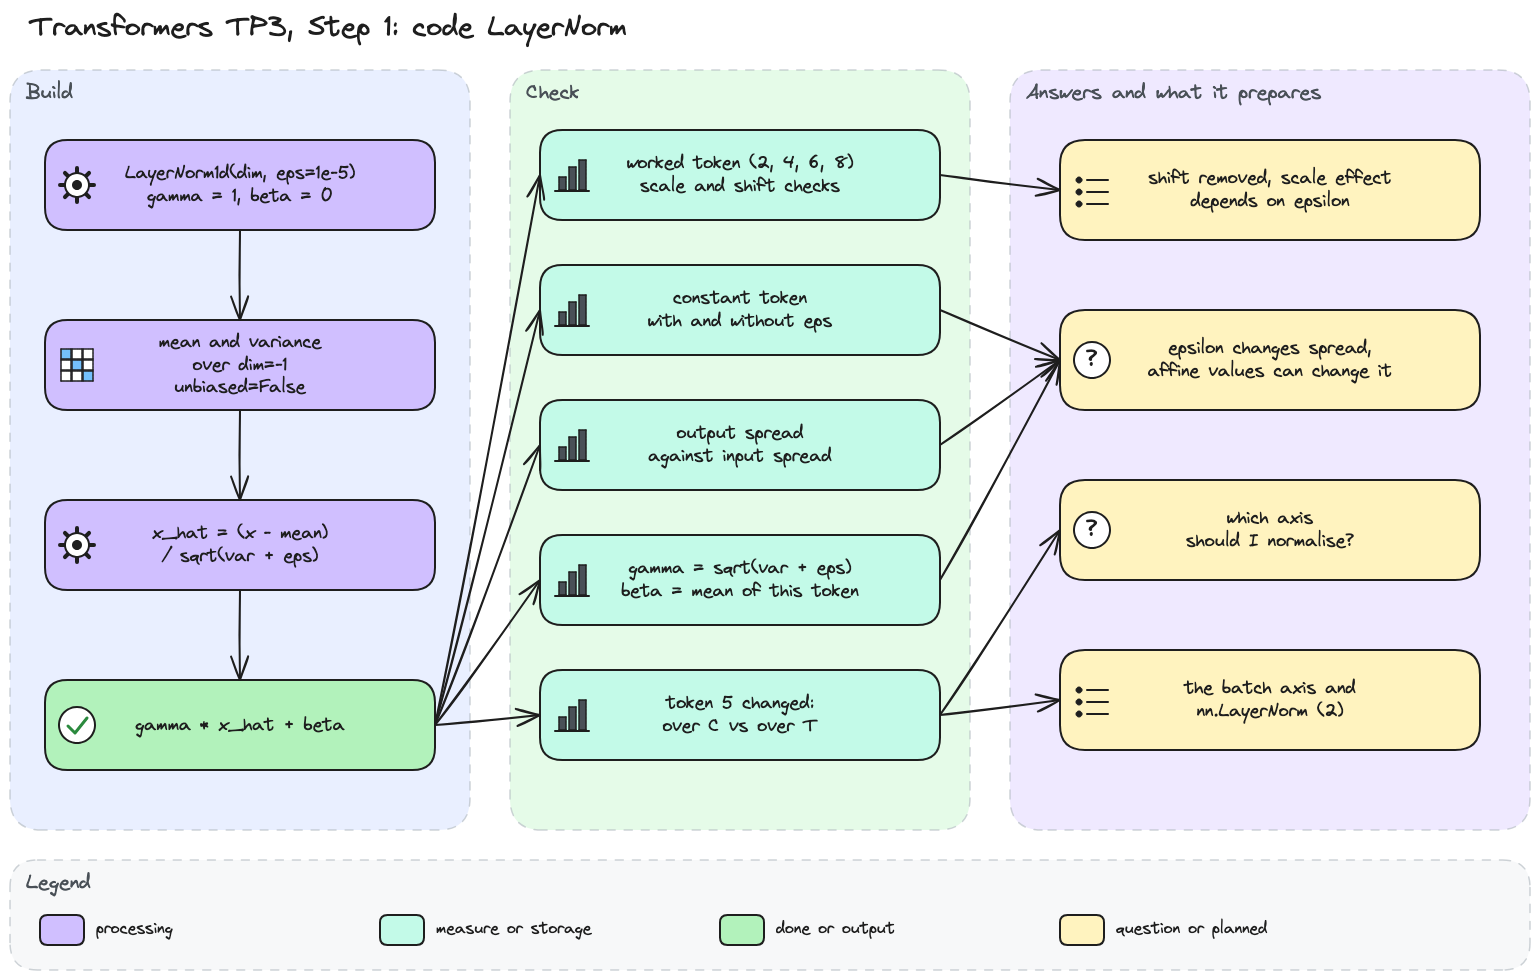

In [4]:
# Step 1 diagram: my LayerNorm, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp3_step1.png', width=900))

In [5]:
# My LayerNorm: mean and variance over the components of each token, then gamma and beta.
class LayerNorm1d:
    """Normalise each vector over its last dimension, then scale by gamma and shift by beta."""

    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        xmean = x.mean(dim=-1, keepdim=True)
        xvar = x.var(
            dim=-1, keepdim=True, unbiased=False
        )
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        return self.gamma * xhat + self.beta

I take statistics over `dim=-1`, the C components of one token. The variance divides by C through `unbiased=False`, and epsilon enters the denominator inside the square root.

This small class stores gamma and beta as ordinary tensors. It exposes the formula, but these tensors are not registered trainable parameters as they are in `nn.LayerNorm`.

Token (2, 4, 6, 8): mean 5, variance 5
[2.0, 4.0, 6.0, 8.0] -> [-1.34, -0.45, 0.45, 1.34]
[20.0, 40.0, 60.0, 80.0] -> [-1.34, -0.45, 0.45, 1.34]
[102.0, 104.0, 106.0, 108.0] -> [-1.34, -0.45, 0.45, 1.34]
Largest absolute mean of the outputs: 3.0e-08, std of each output: [1.0, 1.0, 1.0]


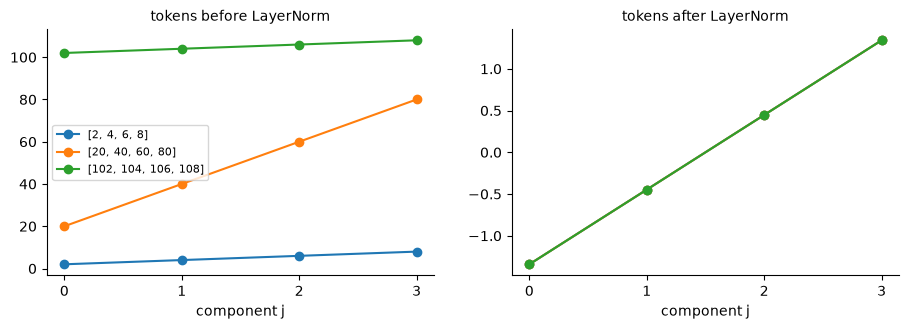

In [6]:
# What does LayerNorm remove? Three tokens of the same shape, at different scales and shifts.
import matplotlib.pyplot as plt

norm = LayerNorm1d(4)
tokens = torch.tensor([[2., 4., 6., 8.], [20., 40., 60., 80.], [102., 104., 106., 108.]])
first = tokens[0]
normed = norm(tokens)

print(f'Token (2, 4, 6, 8): mean {first.mean():.0f}, variance {first.var(unbiased=False):.0f}')
for token, row in zip(tokens.tolist(), normed.tolist()):
    print(f'{token} -> {[round(value, 2) for value in row]}')
print(f'Largest absolute mean of the outputs: {normed.mean(dim=-1).abs().max():.1e}, '
      f'std of each output: {[round(s, 3) for s in normed.std(dim=-1, unbiased=False).tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for token, row in zip(tokens, normed):
    axes[0].plot(range(4), token, marker='o', label=str(token.int().tolist()))
    axes[1].plot(range(4), row, marker='o')
for ax, title in ((axes[0], 'tokens before LayerNorm'), (axes[1], 'tokens after LayerNorm')):
    ax.set_xticks(range(4))
    ax.set_xlabel('component j')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

The three outputs round to the same values, with means within 3.0e-08 of zero and standard deviations displayed as 1.0. Rounded values alone cannot establish exact invariance or an exact standard deviation of one.

I trace the first token through the formula before accepting my initial hypothesis. This also gives me a reference calculation for checking the implementation.

In [7]:
# Trace the first token without changing the normaliser or drawing random values.
demo_ln_input = first.detach().clone()
demo_ln_mean = demo_ln_input.mean()
demo_ln_centred = demo_ln_input - demo_ln_mean
demo_ln_var = demo_ln_centred.square().mean()
demo_ln_divisor = torch.sqrt(demo_ln_var + norm.eps)
demo_ln_hat = demo_ln_centred / demo_ln_divisor
demo_ln_output = norm.gamma.detach() * demo_ln_hat + norm.beta.detach()
demo_ln_reference = torch.nn.functional.layer_norm(demo_ln_input, (4,), eps=norm.eps)
demo_ln_expected_var = demo_ln_var / (demo_ln_var + norm.eps)
assert torch.allclose(demo_ln_output, norm(first), atol=1e-6)
assert torch.allclose(demo_ln_output, demo_ln_reference, atol=1e-6)
assert torch.allclose(demo_ln_hat.var(unbiased=False), demo_ln_expected_var, atol=1e-7)

print(f'mean {demo_ln_mean.item():.1f}, centred values {demo_ln_centred.tolist()}')
print(f'population variance {demo_ln_var.item():.1f}, divisor {demo_ln_divisor.item():.8f}')
print(f'gamma {norm.gamma.tolist()}, beta {norm.beta.tolist()}')
print(f'output {[round(v, 7) for v in demo_ln_output.tolist()]}')
print(f'variance before affine {demo_ln_hat.var(unbiased=False).item():.8f}, '
      f'variance / (variance + eps) {demo_ln_expected_var.item():.8f}')

mean 5.0, centred values [-3.0, -1.0, 1.0, 3.0]
population variance 5.0, divisor 2.23607016
gamma [1.0, 1.0, 1.0, 1.0], beta [0.0, 0.0, 0.0, 0.0]
output [-1.3416395, -0.4472132, 0.4472132, 1.3416395]
variance before affine 0.99999809, variance / (variance + eps) 0.99999797


The centred components are -3, -1, 1 and 3, whose squared values average to five. Dividing by sqrt(5 + epsilon) agrees with both implementations within the asserted tolerances.

The variance before the affine step is variance / (variance + epsilon), so it is slightly below one even here. The two printed variances differ in their last digits because equivalent expressions are evaluated in float32.

I next test a constant token, where the denominator depends entirely on epsilon.

In [8]:
# Why eps? A constant token has a variance of 0, normalised with and without eps.
constant = torch.full((1, 4), 5.0)
print(f'Variance of (5, 5, 5, 5): {constant.var(unbiased=False).item()}')
print(f'With eps = 1e-5: {norm(constant).tolist()}')
print(f'With eps = 0: {LayerNorm1d(4, eps=0.0)(constant).tolist()}')

Variance of (5, 5, 5, 5): 0.0
With eps = 1e-5: [[0.0, 0.0, 0.0, 0.0]]
With eps = 0: [[nan, nan, nan, nan]]


The constant token has variance zero. With epsilon zero, the calculation divides zero by zero and produces NaNs, while epsilon 1e-5 gives zeros with the default affine values.

This explains why I keep epsilon in the denominator. I next vary the spread while fixing the mean and epsilon to see whether that stabiliser also changes nonconstant tokens.

spread 0.0001: output std 0.032
spread 0.0003: output std 0.094
spread 0.001: output std 0.302
spread 0.003: output std 0.688
spread 0.01: output std 0.953
spread 0.03: output std 0.994
spread 0.1: output std 1.000
spread 1: output std 1.000
sqrt(eps) = 0.0032


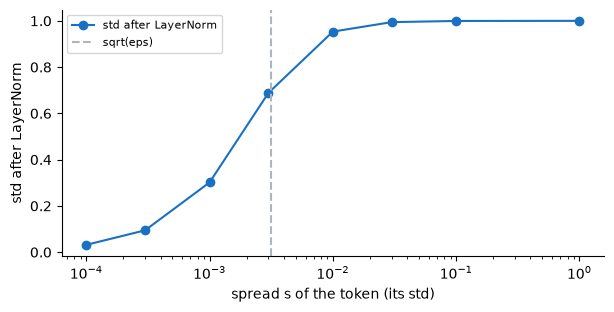

In [9]:
# How much does eps damp a token with a small spread? Output std of (-s, s, -s, s) against s.
import math

SPREADS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.0]
output_stds = []
for s in SPREADS:
    output_stds.append(norm(torch.tensor([-s, s, -s, s])).std(unbiased=False).item())
    print(f'spread {s:g}: output std {output_stds[-1]:.3f}')
print(f'sqrt(eps) = {math.sqrt(norm.eps):.4f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(SPREADS, output_stds, marker='o', color='#1971c2', label='std after LayerNorm')
ax.axvline(math.sqrt(norm.eps), linestyle='--', color='#adb5bd', label='sqrt(eps)')
ax.set_xscale('log')
ax.set_xlabel('spread s of the token (its std)')
ax.set_ylabel('std after LayerNorm')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

At spread 0.03, the output standard deviation is 0.994, already below one. At 0.003, near the displayed square root of epsilon, it is 0.688, and at 0.0001 it is 0.032.

For these tokens, the formula is s / sqrt(s² + epsilon). I therefore revise my first hypothesis because epsilon changes the output spread, especially when the input variance is small.

The experiment does not tell me whether a small input variation is signal or noise. It shows how strongly the formula rescales that variation.

I next keep the formula and inspect how gamma and beta rescale and shift its normalised values.

In [10]:
# What are gamma and beta for? Their starting values, then a choice that undoes the normalisation.
import torch.nn as nn

print(f'gamma: {norm.gamma.tolist()}, beta: {norm.beta.tolist()}')
print(f'Affine entries for C = 4: {norm.gamma.numel() + norm.beta.numel()}, '
      f'nn.LayerNorm(4): {sum(p.numel() for p in nn.LayerNorm(4).parameters())}')

undo = LayerNorm1d(4)
undo.gamma = torch.sqrt(first.var(unbiased=False) + undo.eps).expand(4)  # the divisor itself
undo.beta = first.mean().expand(4)
print(f'gamma = sqrt(variance + eps), beta = mean: {undo(first).tolist()}, '
      f'largest gap {(undo(first) - first).abs().max().item():.1e}')

gamma: [1.0, 1.0, 1.0, 1.0], beta: [0.0, 0.0, 0.0, 0.0]
Affine entries for C = 4: 8, nn.LayerNorm(4): 8
gamma = sqrt(variance + eps), beta = mean: [2.0, 4.0, 6.0, 8.0], largest gap 0.0e+00


Gamma starts at one and beta at zero, so the affine step initially leaves the normalised values unchanged. There are eight affine entries for four components, matching the parameter count of `nn.LayerNorm(4)`.

Using this particular token's denominator as gamma and its mean as beta reconstructs it with a displayed gap of zero. I supplied those statistics explicitly, so this does not show that shared affine parameters can recover every token's original statistics.

Trainable affine parameters can change the output mean and spread after normalisation. I next keep the formula fixed and change the axis to test which tokens can influence each other.

over C, the components: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 2.49, 0.0, 0.0]
over T, the positions: largest change per row [0.85, 0.53, 1.01, 0.68, 0.66, 2.17, 0.87, 0.61]


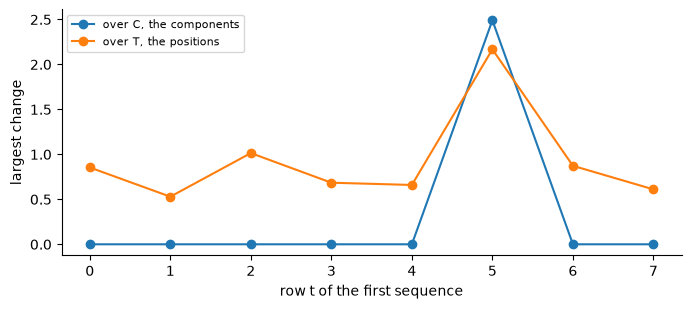

In [11]:
# Which axis? Token 5 of the first sequence replaced, then normalised over C and over T.
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
changed = x.clone()
changed[0, 5] = torch.randn(C)

norm_c, norm_t = LayerNorm1d(C), LayerNorm1d(T)
versions = {'over C, the components': norm_c,
            # my class on the transposed tensor takes its statistics over the T positions
            'over T, the positions': lambda x: norm_t(x.transpose(1, 2)).transpose(1, 2)}
moves = {}
for name, normalise in versions.items():
    moves[name] = (normalise(changed) - normalise(x))[0].abs().max(dim=-1).values
    print(f'{name}: largest change per row {[round(v, 2) for v in moves[name].tolist()]}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, move in moves.items():
    ax.plot(range(T), move, marker='o', label=name)
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Over C, changing token 5 moves only its own row, by 2.49. Over T, the other rows move by 0.53 to 1.01, including rows before token 5.

The second calculation uses statistics containing a future token, so it breaks causality for earlier positions. Normalising over C avoids that dependency because every row uses only its own components.

> *My conclusion:*
>
> My first hypothesis needs qualification. With default gamma and beta, the mean is approximately zero, but epsilon makes the population variance smaller than one, and a constant token becomes zero.
>
> Positive scaling gives similar outputs when epsilon is small relative to the variance. The rounded agreement of the first three examples does not establish exact equality.
>
> My answers to the two questions of this step:
>
> 1. I normalise over C with `dim=-1`. Normalising over all T positions lets a future token affect earlier outputs.
> 2. Epsilon keeps the division defined. Gamma and beta rescale and shift each component, with one shared pair of vectors across tokens.
>
> Section 2 checks the batch interpretation and compares the formula with `nn.LayerNorm`.

## 2. Choose the normalisation axis

I now separate a token's features from one feature observed across a batch. On a tensor with 32 rows and 100 columns, I predict the two statistics before running the calculation.

I then change individual inputs and compare against `nn.LayerNorm`. These tests address dependency and numerical agreement, which the shape alone cannot establish.

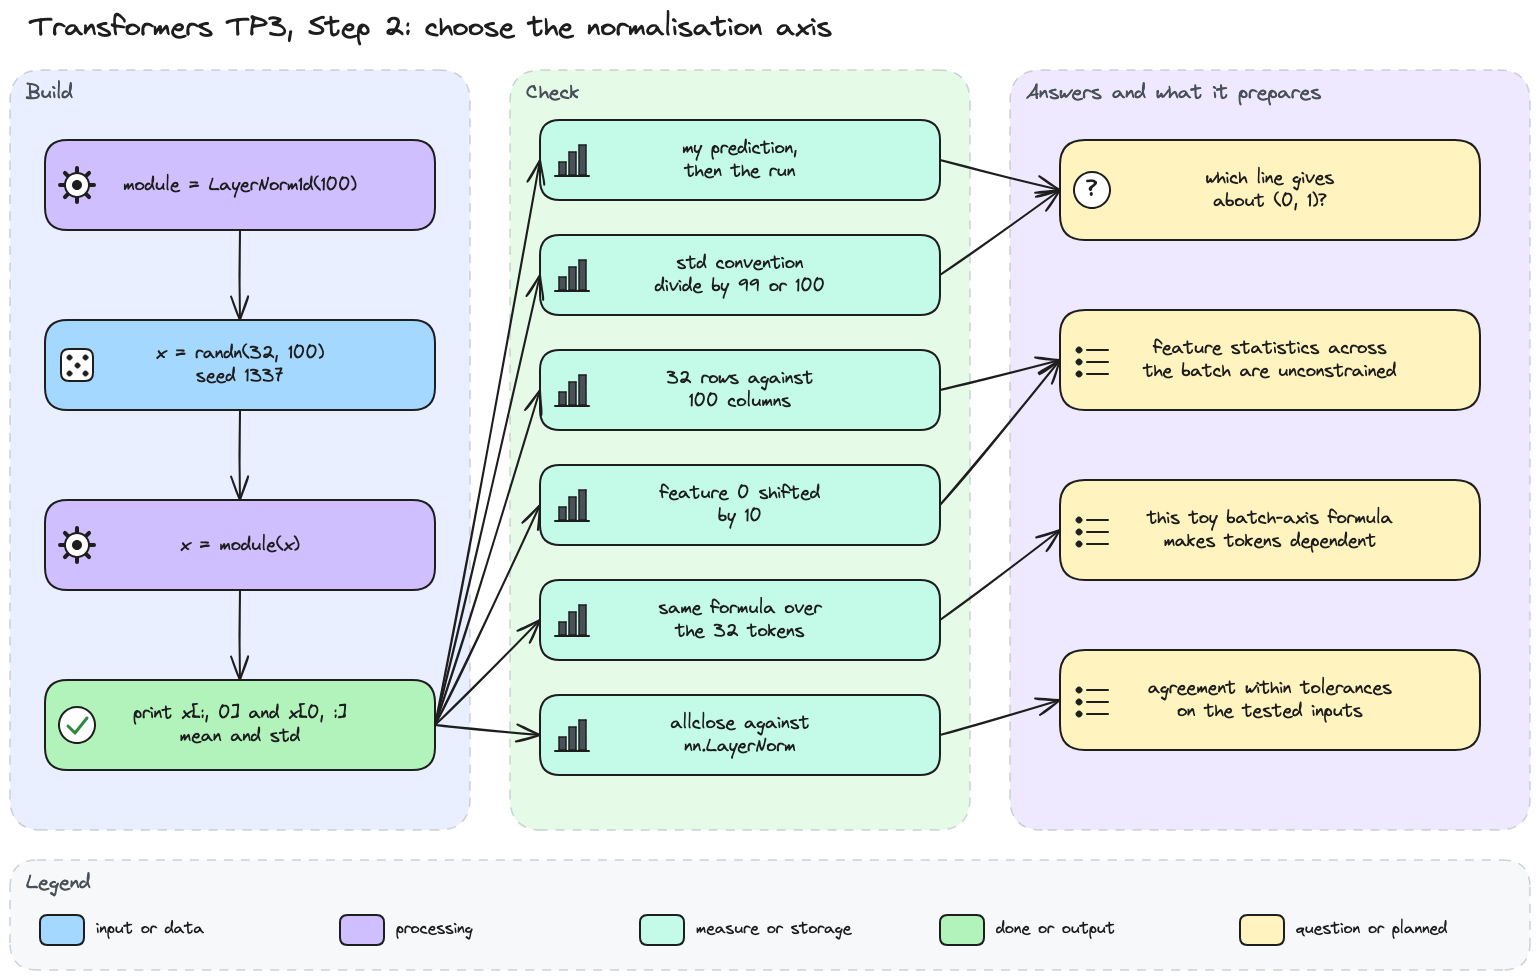

In [12]:
# Step 2 diagram: the initial example, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp3_step2.png', width=900))

`x[0, :]` contains one token's 100 features, the axis used by my formula. With default affine values and a substantial input variance, I expect its mean and standard deviation to be near zero and one.

`x[:, 0]` contains one feature across 32 tokens. My formula takes no statistics over that axis, so I expect no fixed mean or standard deviation there.

In [13]:
# Which line gives about (0, 1)? The initial example, run after writing my prediction.
torch.manual_seed(1337)
module = LayerNorm1d(100)

x = torch.randn(32, 100)
x = module(x)

print(x[:, 0].mean(), x[:, 0].std())
print(x[0, :].mean(), x[0, :].std())

tensor(0.1476) tensor(0.8847)
tensor(-2.3842e-09) tensor(1.0050)


The token's mean is approximately -2.4e-09 and its displayed standard deviation is 1.0050. The feature across tokens gives 0.1476 and 0.8847, consistent with my prediction that this axis is unconstrained.

Before treating the difference from one as an implementation error, I check which variance convention `.std()` uses. The next calculation changes only that convention on the same output.

In [14]:
# Why 1.0050 and not 1? The same std with the division by 100 that my LayerNorm uses.
print(f'x[0, :].std(unbiased=False): {x[0, :].std(unbiased=False):.4f}')
print(f'sqrt(100 / 99) = {math.sqrt(100 / 99):.4f}')

x[0, :].std(unbiased=False): 1.0000
sqrt(100 / 99) = 1.0050


With `unbiased=False`, the standard deviation rounds to 1.0000. The default `.std()` divides by 99, so its value is multiplied by sqrt(100 / 99), which rounds to 1.0050.

That difference comes from the variance convention rather than rounding alone. Epsilon still prevents the population standard deviation from being exactly one.

I next inspect every row and column to check whether the first token and feature hide a different pattern elsewhere.

32 tokens, x[i, :]: means from -0.00 to 0.00, stds from 1.000 to 1.000
100 features, x[:, j]: means from -0.59 to 0.42, stds from 0.742 to 1.399


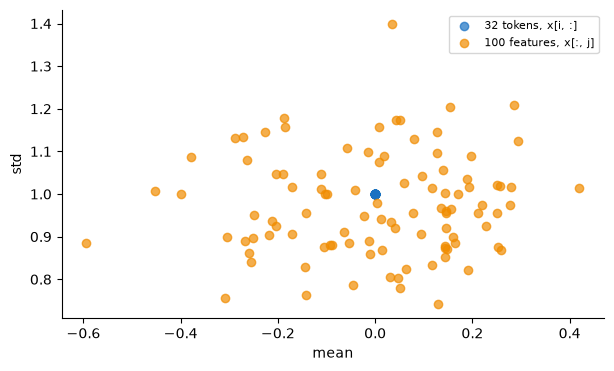

In [15]:
# What is fixed and what is free? Mean and std of the 32 tokens (rows) and the 100 features.
stats = {'32 tokens, x[i, :]': (x.mean(dim=1), x.std(dim=1, unbiased=False)),
         '100 features, x[:, j]': (x.mean(dim=0), x.std(dim=0, unbiased=False))}
for name, (means, stds) in stats.items():
    print(f'{name}: means from {means.min():.2f} to {means.max():.2f}, '
          f'stds from {stds.min():.3f} to {stds.max():.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
for (name, (means, stds)), color in zip(stats.items(), ('#1971c2', '#f08c00')):
    ax.scatter(means, stds, color=color, alpha=0.7, label=name)
ax.set_xlabel('mean')
ax.set_ylabel('std')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

All 32 token means round to zero and their population standard deviations to 1.000. The 100 feature means range from -0.59 to 0.42, with standard deviations from 0.742 to 1.399.

These random inputs happen to leave feature statistics fairly close to zero and one. I test whether that appearance comes from the input by shifting one feature while keeping every other raw value fixed.

Same input as the initial example: True
Feature 0: mean 0.15, std 0.87 without the shift, mean 7.08, std 0.44 with it
Feature 1: mean -0.59, std 0.89 without the shift, mean -0.49, std 0.64 with it
Tokens: largest absolute mean 2.9e-08, stds from 1.000 to 1.000


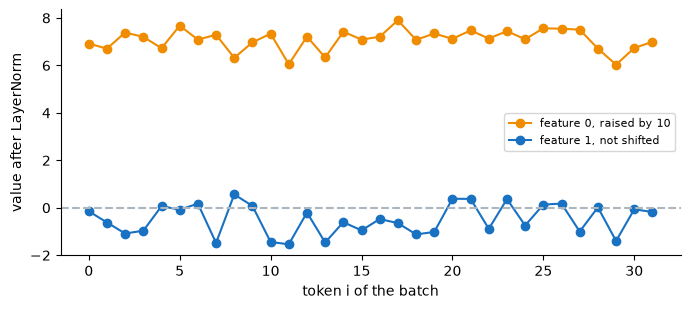

In [16]:
# Can a feature escape the normalisation? Feature 0 raised by 10 in every token, then LayerNorm.
torch.manual_seed(1337)
raw = torch.randn(32, 100)  # the original input, before normalisation
print(f'Same input as the initial example: {torch.equal(module(raw), x)}')

shifted = raw.clone()
shifted[:, 0] += 10
out = module(shifted)
for j in (0, 1):
    print(f'Feature {j}: mean {x[:, j].mean():.2f}, std {x[:, j].std(unbiased=False):.2f} '
          f'without the shift, mean {out[:, j].mean():.2f}, '
          f'std {out[:, j].std(unbiased=False):.2f} with it')
print(f'Tokens: largest absolute mean {out.mean(dim=1).abs().max():.1e}, stds from '
      f'{out.std(dim=1, unbiased=False).min():.3f} to {out.std(dim=1, unbiased=False).max():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(32), out[:, 0], marker='o', color='#f08c00', label='feature 0, raised by 10')
ax.plot(range(32), out[:, 1], marker='o', color='#1971c2', label='feature 1, not shifted')
ax.axhline(0, linestyle='--', color='#adb5bd')
ax.set_xlabel('token i of the batch')
ax.set_ylabel('value after LayerNorm')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Raising feature zero by 10 moves its normalised mean from 0.15 to 7.08 and its standard deviation from 0.87 to 0.44. It remains large across tokens because LayerNorm imposes no statistics along that axis.

Feature one also changes, although I left its raw values untouched. Its mean moves from -0.59 to -0.49 because the changed component affects each token's shared mean and denominator.

Components within a token therefore interact through normalisation. I next replace one entire token to check whether that dependency extends across the batch.

over the features, LayerNorm: token 0 moves by 0.00, tokens other than 5 by up to 0.00
over the 32 tokens of the batch: token 0 moves by 0.27, tokens other than 5 by up to 0.43
One token alone, over the batch: largest value 0.0
One token alone, LayerNorm: same output as in the batch True


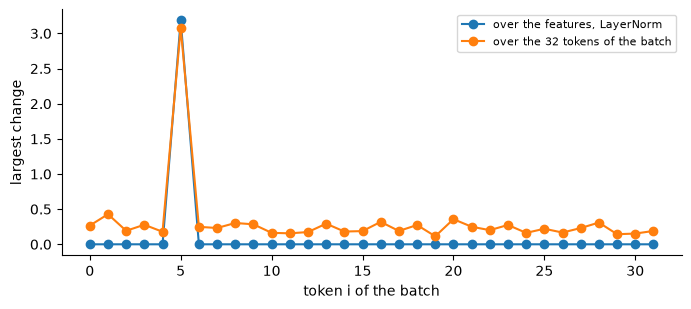

In [17]:
# What if the statistics went over the batch? Token 5 replaced, then both axes on the 32 tokens.
changed = raw.clone()
changed[5] = torch.randn(100)
norm_batch = LayerNorm1d(32)
batch_versions = {'over the features, LayerNorm': module,
                  # my class on the transposed tensor takes its statistics over the 32 tokens
                  'over the 32 tokens of the batch': lambda x: norm_batch(x.T).T}
moves = {}
for name, normalise in batch_versions.items():
    moves[name] = (normalise(changed) - normalise(raw)).abs().max(dim=1).values
    others = torch.cat([moves[name][:5], moves[name][6:]])
    print(f'{name}: token 0 moves by {moves[name][0]:.2f}, '
          f'tokens other than 5 by up to {others.max():.2f}')

alone = raw[:1]
print(f'One token alone, over the batch: largest value {LayerNorm1d(1)(alone.T).T.abs().max():.1f}')
print(f'One token alone, LayerNorm: same output as in the batch '
      f'{torch.allclose(module(alone), module(raw)[:1])}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, move in moves.items():
    ax.plot(range(32), move, marker='o', label=name)
ax.set_xlabel('token i of the batch')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With statistics over features, replacing token 5 leaves every other token unchanged. Taking statistics over the batch instead moves token zero by 0.27 and other tokens by up to 0.43.

A single token becomes zero under this batch-axis formula, while feature-wise LayerNorm gives the same output alone or inside the batch. This is a toy axis comparison, not a complete implementation of BatchNorm with its training and evaluation behaviour.

For these token operations, I want outputs independent of unrelated batch members. I keep the feature axis and now check the numerical formula against PyTorch.

In [18]:
# Does my class match nn.LayerNorm? The initial check, then the largest gap on three inputs.
print(torch.allclose(module(x), nn.LayerNorm(100)(x), atol=1e-6))

reference = nn.LayerNorm(100)
for name, inputs in (('x, already normalised', x), ('raw input', raw),
                     ('raw * 50 + 7', raw * 50 + 7)):
    print(f'{name}: largest gap {(module(inputs) - reference(inputs)).abs().max():.1e}')
print(f'float32 epsilon: {torch.finfo(torch.float32).eps:.2e}')

True
x, already normalised: largest gap 4.8e-07
raw input: largest gap 4.8e-07
raw * 50 + 7: largest gap 4.8e-07
float32 epsilon: 1.19e-07


The comparisons pass on already normalised inputs, raw inputs and shifted, scaled raw inputs. The largest displayed gap is 4.8e-07, consistent with small floating-point differences between implementations.

`allclose` checks each absolute difference against `atol + rtol * abs(reference)`. Here `atol` is 1e-6 and the default `rtol` is 1e-5, so this is a tolerance check rather than mathematical identity.

A passing check can still miss bugs outside these inputs. Default gamma and beta also hide some affine mistakes, so I next copy identical random affine values into both implementations.

In [19]:
# Do gamma, beta and the variance match too? Random gamma and beta in both, then Bessel's variance.
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    reference.weight.normal_()
    reference.bias.normal_()
mine = LayerNorm1d(100)
mine.gamma, mine.beta = reference.weight.detach().clone(), reference.bias.detach().clone()
print(f'Random gamma and beta in both: largest gap {(mine(raw) - reference(raw)).abs().max():.1e}, '
      f'allclose {torch.allclose(mine(raw), reference(raw), atol=1e-6)}, '
      f'largest |gamma| {mine.gamma.abs().max():.2f}')

unbiased = (raw - raw.mean(-1, keepdim=True)) / torch.sqrt(raw.var(-1, keepdim=True) + mine.eps)
print(f'Variance divided by 99 instead of 100: largest gap '
      f'{(unbiased - nn.LayerNorm(100)(raw)).abs().max():.3f}')

Random gamma and beta in both: largest gap 1.4e-06, allclose True, largest |gamma| 2.22
Variance divided by 99 instead of 100: largest gap 0.017


With shared random gamma and beta, the maximum gap is 1.4e-06 and `allclose` still passes. The relative tolerance explains why a difference above the absolute tolerance can be accepted.

Using division by 99 instead produces a gap of 0.017. That check supports the population-variance formula used by `nn.LayerNorm`, while the random affine test exercises the scaling and shifting separately.

> *My conclusion:*
>
> The row and feature predictions hold for the default affine values. The standard deviation near one depends on both epsilon and the convention used to report it.
>
> The formula matches PyTorch within the tested tolerances, including copied affine values. This supports using it for the next experiments without claiming that a finite set of checks proves every case.
>
> My answer to the question of this step:
>
> - `x[0, :]` gives approximately -2.4e-09 and 1.0050, or 1.0000 with population standard deviation. `x[:, 0]` gives 0.1476 and 0.8847 with no imposed values.

## 3. Build the feed-forward network

I want each token to undergo a shared transformation without exchanging information with other positions. I use two projections around a ReLU, widening from C to 4C before returning to C.

I first check the calculation and shapes, then test token independence and the role of the activation. Keeping the same weights for these comparisons helps isolate what each change does.

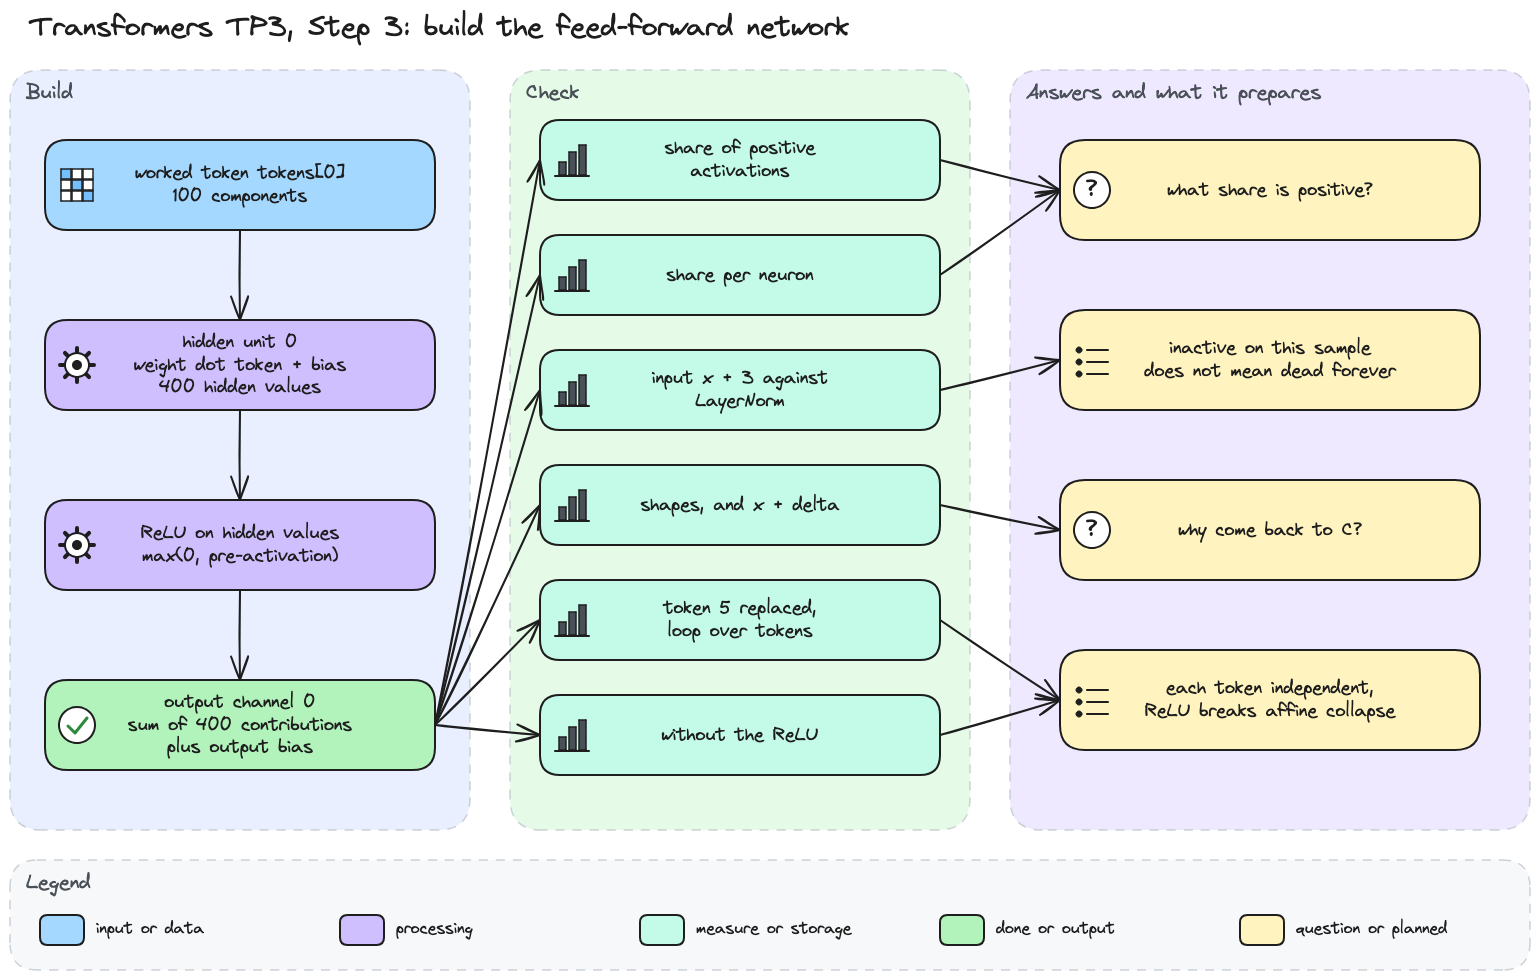

In [20]:
# Step 3 diagram: the network C -> 4C -> C, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp3_step3.png', width=900))

In [21]:
# The feed-forward network: widen each token to 4C, apply ReLU, come back to C.
class FeedForward(nn.Module):
    """Linear C to 4C, ReLU, then Linear 4C to C, on the last dimension of x."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x):
        return self.net(x)

Both projections operate on the last dimension, so the same class should accept a batch or a batch of sequences. Returning to C prepares an output that can be added to the input.

I reset seed 1337 before constructing the network and input. That makes this example reproducible without depending on how many random draws the earlier checks consumed.

In [22]:
# The initial example, with a seed so that the draw does not depend on the cells above.
torch.manual_seed(1337)
ffwd = FeedForward(100)
delta = ffwd(torch.randn(32, 100))
print(delta.shape)

torch.Size([32, 100])


The output has shape (32, 100), matching the input. This checks compatibility but says nothing about which hidden values contributed to it.

I repeat the same seeded construction to recover the input tokens and check that the output is unchanged. I can then inspect the hidden values without introducing a new experiment.

In [23]:
# What share of the hidden activations is positive? The same draw, read before and after the ReLU.
torch.manual_seed(1337)
ffwd = FeedForward(100)
tokens = torch.randn(32, 100)
print(f'Same delta as the initial example: {torch.equal(ffwd(tokens), delta)}')

pre = ffwd.net[0](tokens)  # after Linear(C, 4C), before the ReLU
hidden = ffwd.net[1](pre)
print(f'Across all hidden entries before ReLU: {tuple(pre.shape)}, '
      f'mean {pre.mean():.3f}, std {pre.std():.3f}')
print(f'After the ReLU: positive {100 * (hidden > 0).float().mean():.2f}%, '
      f'exactly zero {100 * (hidden == 0).float().mean():.2f}% of {hidden.numel():,} values')

Same delta as the initial example: True
Across all hidden entries before ReLU: (32, 400), mean 0.008, std 0.565
After the ReLU: positive 50.74%, exactly zero 49.26% of 12,800 values


Across all 12,800 hidden values, the pre-activation mean is 0.008 and the standard deviation is 0.565. These are aggregate statistics, not the statistics of each token separately.

ReLU leaves 50.74% positive and sets 49.26% to zero, supporting my approximate-half hypothesis for this draw. A mean near zero alone would not guarantee that split because the distribution's shape also matters.

I trace one token next to connect the activation count with an actual output calculation.

In [24]:
# Trace hidden unit zero and output channel zero using detached copies of the existing weights.
demo_ff_token = tokens[0].detach().clone()
demo_ff_up = ffwd.net[0].weight.detach().clone()
demo_ff_up_bias = ffwd.net[0].bias.detach().clone()
demo_ff_down = ffwd.net[2].weight.detach().clone()
demo_ff_down_bias = ffwd.net[2].bias.detach().clone()
demo_ff_pre = demo_ff_up @ demo_ff_token + demo_ff_up_bias
demo_ff_hidden = demo_ff_pre.clamp_min(0)
demo_ff_contributions = demo_ff_down[0] * demo_ff_hidden
demo_ff_output = demo_ff_contributions.sum() + demo_ff_down_bias[0]
assert torch.allclose(demo_ff_pre[0], pre[0, 0].detach(), atol=1e-6)
assert torch.allclose(demo_ff_hidden, hidden[0].detach(), atol=1e-6)
assert torch.allclose(demo_ff_output, delta[0, 0].detach(), atol=1e-6)

print(f'hidden unit 0 dot product {(demo_ff_up[0] @ demo_ff_token).item():.6f}, '
      f'bias {demo_ff_up_bias[0].item():.6f}')
print(f'hidden unit 0 before ReLU {demo_ff_pre[0].item():.6f}, '
      f'after ReLU {demo_ff_hidden[0].item():.6f}')
print(f'unit 0 contribution to output 0 {demo_ff_contributions[0].item():.6f}')
print(f'sum of {demo_ff_contributions.numel()} contributions '
      f'{demo_ff_contributions.sum().item():.6f}, output bias {demo_ff_down_bias[0].item():.6f}')
print(f'output channel 0 {demo_ff_output.item():.6f}, '
      f'existing delta {delta[0, 0].item():.6f}')

hidden unit 0 dot product -0.204222, bias 0.098062
hidden unit 0 before ReLU -0.106160, after ReLU 0.000000
unit 0 contribution to output 0 -0.000000
sum of 400 contributions -0.150153, output bias -0.022314
output channel 0 -0.172466, existing delta -0.172466


The first projection forms a weighted sum of this token's components and adds its bias. Here hidden unit zero reaches -0.106160, so ReLU sets it to zero and it contributes nothing to output channel zero.

The second projection combines all hidden contributions and adds its own bias, giving -0.172466. This agrees with the existing output, using no other token.

I now inspect activation shares per neuron because the aggregate percentage could hide consistently inactive units on this sample.

Per neuron: from 21.88% to 78.12%, inactive on all sampled tokens 0, active on all sampled tokens 0
Per token: from 45.50% to 56.75% of the 400 neurons


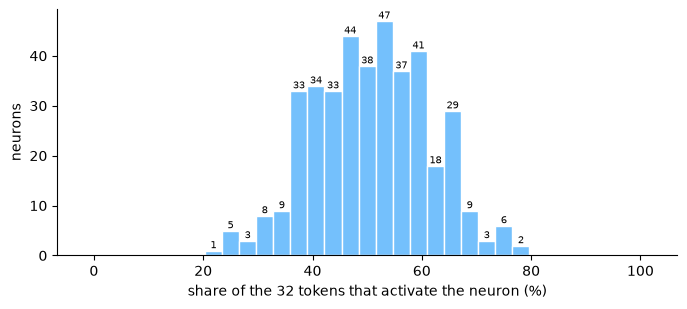

In [25]:
# How do active shares vary? Share of the 32 tokens that activate each of the 400 neurons.
EDGES = [100 * (k - 0.5) / 32 for k in range(34)]  # one bin per possible share, k / 32
active = (hidden > 0).float()
per_neuron, per_token = active.mean(dim=0), active.mean(dim=1)
print(f'Per neuron: from {100 * per_neuron.min():.2f}% to {100 * per_neuron.max():.2f}%, '
      f'inactive on all sampled tokens {(per_neuron == 0).sum().item()}, '
      f'active on all sampled tokens {(per_neuron == 1).sum().item()}')
print(f'Per token: from {100 * per_token.min():.2f}% to {100 * per_token.max():.2f}% '
      f'of the 400 neurons')

fig, ax = plt.subplots(figsize=(8, 3.2))
counts, _, bars = ax.hist(100 * per_neuron, bins=EDGES, color='#74c0fc', edgecolor='white')
ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=7)
ax.set_xlabel('share of the 32 tokens that activate the neuron (%)')
ax.set_ylabel('neurons')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Each hidden neuron is active on between 21.88% and 78.12% of the 32 tokens. None is inactive on every sampled token, and each token activates between 45.50% and 56.75% of the neurons.

These marginal counts do not identify the full activation pattern of each token. They also cannot establish whether a neuron would remain inactive on future inputs or during training.

I keep the weights and tokens fixed, then add the same offset to every component. This tests how activation patterns depend on the input distribution.

tokens: 50.74% active, inactive on this sample 0, active on every sampled token 0
tokens + 3: 47.59% active, inactive on this sample 93, active on every sampled token 100
my LayerNorm(tokens + 3): 50.77% active, inactive on this sample 0, active on every sampled token 0


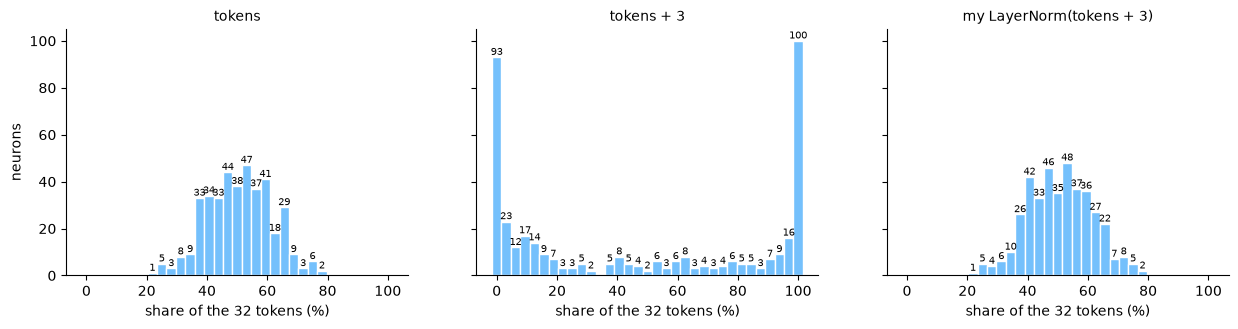

In [26]:
# Does the input offset matter? Active share per neuron for three versions of the same tokens.
inputs = {'tokens': tokens, 'tokens + 3': tokens + 3,
          'my LayerNorm(tokens + 3)': module(tokens + 3)}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, (name, z) in zip(axes, inputs.items()):
    share = (ffwd.net[1](ffwd.net[0](z)) > 0).float().mean(dim=0)
    print(f'{name}: {100 * share.mean():.2f}% active, '
          f'inactive on this sample {(share == 0).sum().item()}, '
          f'active on every sampled token {(share == 1).sum().item()}')
    counts, _, bars = ax.hist(100 * share, bins=EDGES, color='#74c0fc', edgecolor='white')
    ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=7)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('share of the 32 tokens (%)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('neurons')
plt.show()

Adding three leaves 93 neurons inactive on all sampled tokens and 100 active on all of them. The overall active share is still 47.59%, so a global average hides this change.

Normalising the shifted inputs gives 50.77% active, with no neuron always inactive or always active on this sample. The normalisation changes spread as well as removing the shared offset.

An inactive ReLU has zero local slope for that input. These results motivate examining pre-normalisation, but they do not show that it guarantees useful neurons or successful training.

In [27]:
# Why come back to C? The shape after each layer on (B, T, C), then x + hidden against x + delta.
B, T, C = 4, 8, 100
x = torch.randn(B, T, C)
print(f'x: {tuple(x.shape)}')
h = x
for layer in ffwd.net:
    h = layer(h)
    print(f'after {layer}: {tuple(h.shape)}')

try:
    x + ffwd.net[1](ffwd.net[0](x))
except RuntimeError as error:
    print(f'x + hidden at 4C fails: {error}')
print(f'x + ffwd(x): {tuple((x + ffwd(x)).shape)}')

x: (4, 8, 100)
after Linear(in_features=100, out_features=400, bias=True): (4, 8, 400)
after ReLU(): (4, 8, 400)
after Linear(in_features=400, out_features=100, bias=True): (4, 8, 100)
x + hidden at 4C fails: The size of tensor a (100) must match the size of tensor b (400) at non-singleton dimension 2
x + ffwd(x): (4, 8, 100)


The sequence tensor goes from (4, 8, 100) to (4, 8, 400), then back to (4, 8, 100). Adding the hidden representation to the input fails because their final dimensions differ.

Returning to C makes the residual addition possible. The TP2 head returned 16 channels from 32, so a complete attention block would also need compatible output dimensions.

A preserved shape could still hide mixing between tokens. I therefore replace one token and compare whole-tensor evaluation with separate evaluation of every token.

Largest change per row of the first sequence: [0.0, 0.0, 0.0, 0.0, 0.0, 0.69, 0.0, 0.0]
Whole tensor against one token at a time: largest gap 4.2e-07, allclose True


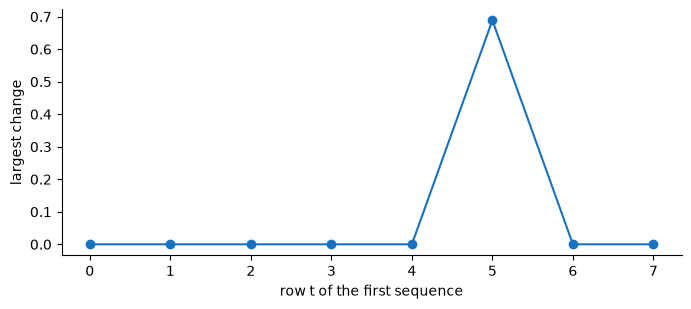

In [28]:
# Does the network mix tokens? Token 5 of the first sequence replaced, then one token at a time.
changed = x.clone()
changed[0, 5] = torch.randn(C)
moves = (ffwd(changed) - ffwd(x))[0].abs().max(dim=-1).values.detach()
print(f'Largest change per row of the first sequence: {[round(v, 2) for v in moves.tolist()]}')

one_by_one = torch.stack([torch.stack([ffwd(x[b, t]) for t in range(T)]) for b in range(B)])
print(f'Whole tensor against one token at a time: largest gap '
      f'{(one_by_one - ffwd(x)).abs().max():.1e}, '
      f'allclose {torch.allclose(one_by_one, ffwd(x), atol=1e-6)}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(T), moves, marker='o', color='#1971c2')
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Replacing token 5 moves only its own row, by 0.69. Whole-tensor and separate-token evaluation agree within 4.2e-07 under the tolerance check.

This matches the structure of the code, where projections use only the last dimension and ReLU acts element by element. My hypothesis of token independence holds for this architecture.

I next remove only ReLU while retaining both projections and their biases. This tests whether the expanded hidden dimension alone creates a different kind of function.

In [29]:
# Is the ReLU needed? Without it, the two Linear layers should be a single Linear(C, C).
up, down = ffwd.net[0], ffwd.net[2]
weight = down.weight @ up.weight  # (C, 4C) @ (4C, C)
bias = down.weight @ up.bias + down.bias
print(f'Merged weight: {tuple(weight.shape)}, rank {torch.linalg.matrix_rank(weight).item()}')
print(f'Two Linear layers without ReLU against x @ weight.T + bias: largest gap '
      f'{(down(up(x)) - (x @ weight.T + bias)).abs().max():.1e}')

Merged weight: (100, 100), rank 100
Two Linear layers without ReLU against x @ weight.T + bias: largest gap 8.9e-07


Without ReLU, the two projections agree with one merged weight and bias within 8.9e-07. The merged matrix has shape (100, 100) and rank 100 in this draw.

The resulting function is affine because it includes a bias. I next fit an affine approximation to both versions on the same sample to measure the remaining discrepancy when ReLU is present.

In [30]:
# How well does an affine fit describe the network on its 2,000 fitting tokens?
torch.manual_seed(RANDOM_STATE)
sample = torch.randn(2000, C)
design = torch.cat([sample, torch.ones(2000, 1)], dim=1)  # a column of ones for the bias
for name, network in (('with ReLU', ffwd), ('without ReLU', lambda z: down(up(z)))):
    target = network(sample).detach()
    fit = design @ torch.linalg.lstsq(design, target).solution
    print(f'{name}: residual / target variance {100 * (fit - target).var() / target.var():.2f}% '
          f'on the affine fitting sample')

with ReLU: residual / target variance 16.64% on the affine fitting sample
without ReLU: residual / target variance 0.00% on the affine fitting sample


On the 2,000 fitting tokens, residual variance divided by target variance is 16.64% with ReLU and rounds to 0.00% without it. Both variances pool the output entries.

This measures the error of an affine approximation on its fitting sample. It is not a fraction of output values or information, and it does not measure performance on unseen tokens.

The comparison shows a discrepancy introduced by ReLU under this metric. It gives no evidence yet about whether that transformation helps language modelling.

> *My conclusion:*
>
> The feed-forward network transforms each token independently and returns to its input dimension. The worked calculation connects one output to the hidden activations and both biases.
>
> About half the activations are positive in the original draw, but the offset experiment shows why I should inspect per-neuron counts too. ReLU also prevents the two projections from collapsing into one affine map.
>
> My answers to the two questions of this step:
>
> 1. On these inputs, 50.74% of the 12,800 hidden activations are positive and 49.26% are zero.
> 2. Returning to C makes the output compatible with the residual addition. The expanded hidden representation cannot be added directly to the input.

## 4. Add the residual connection

I now compute `delta = ffwd(layer_norm(x))` and add it to `x`. Placing normalisation before the branch gives the pre-norm order.

I want to know how much this changes the input and how a gradient crosses the operation. I begin with shapes and magnitudes, then inspect local derivatives and a stack of blocks.

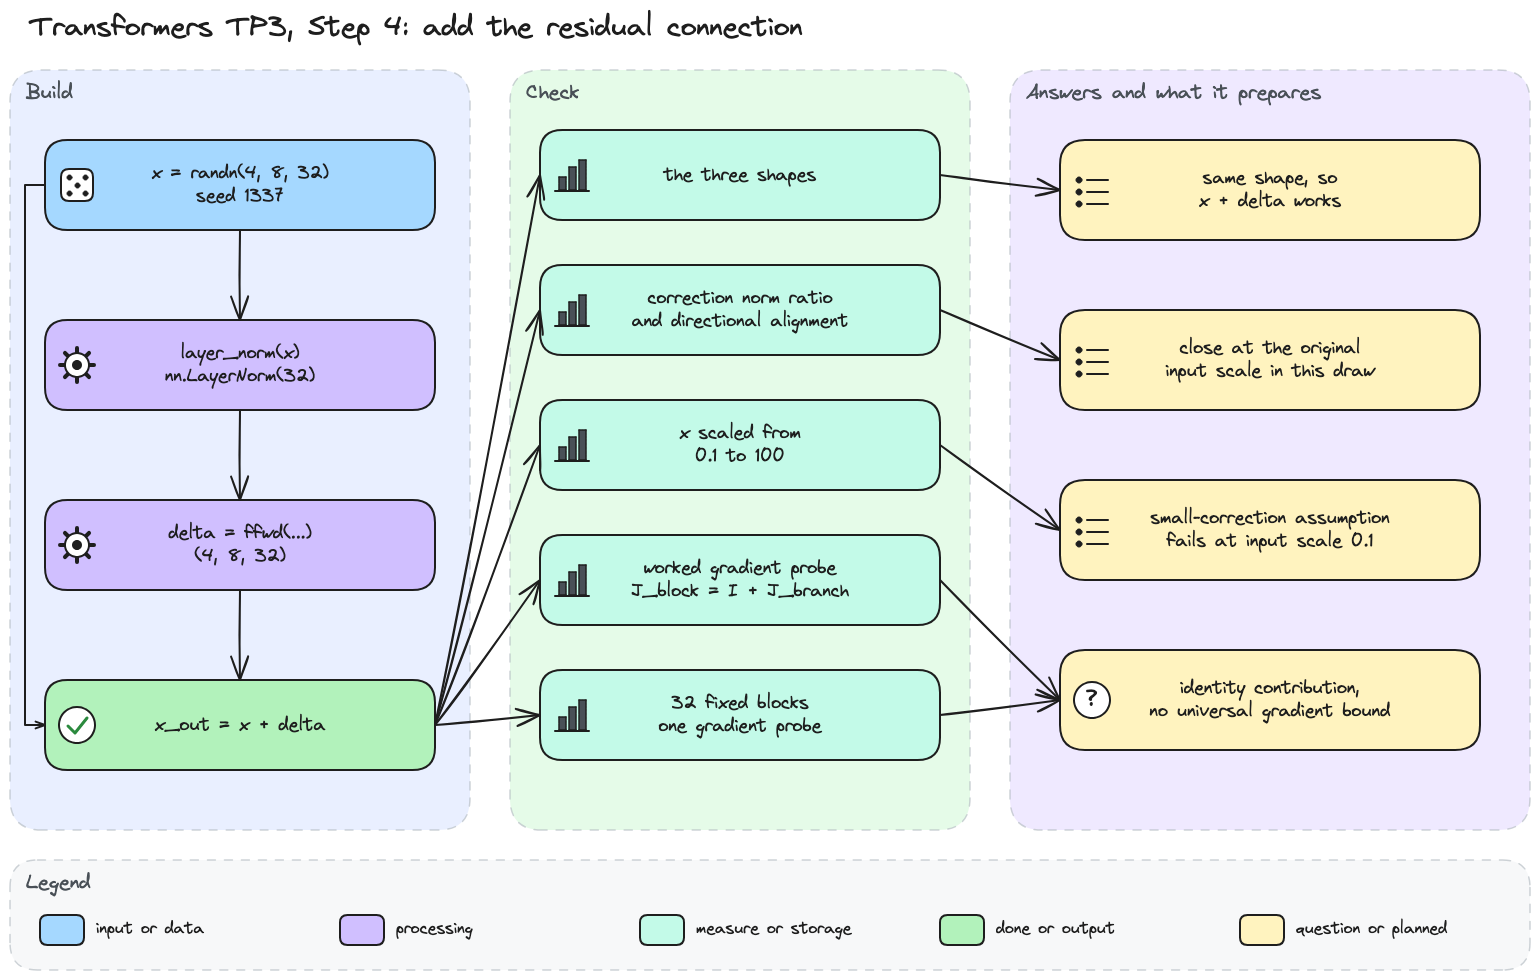

In [31]:
# Step 4 diagram: the pre-norm block, and the checks around its residual addition.
display(Image(filename='diagrams/transformers/tp3_step4.png', width=900))

I use the TP2 dimensions B = 4, T = 8 and C = 32, with seed 1337. These small tensors let me inspect a token's full Jacobian later.

I use `nn.LayerNorm` here because it registers trainable affine parameters alongside the feed-forward parameters. Section 2 checked its numerical agreement with my formula, although this notebook performs no optimiser updates.

In [32]:
# The pre-norm block: LayerNorm, then the feed-forward network, then the residual addition.
torch.manual_seed(1337)
B, T, n_embd = 4, 8, 32
layer_norm = nn.LayerNorm(n_embd)
ffwd = FeedForward(n_embd)

x = torch.randn(B, T, n_embd)
delta = ffwd(layer_norm(x))
x_out = x + delta

print(x.shape)
print(delta.shape)
print(x_out.shape)

torch.Size([4, 8, 32])
torch.Size([4, 8, 32])
torch.Size([4, 8, 32])


Input, branch output and sum all have shape (4, 8, 32). The addition is therefore valid, but matching shapes cannot tell me whether the correction is small.

I measure each token's correction relative to its input norm. Cosine similarity separately measures whether the resulting direction remains close to the input direction.

std of x 0.97, of delta 0.24, of x_out 1.00
||delta|| / ||x|| per token: from 17.02% to 38.15%, mean 25.39%
cosine(x_out, x) per token: from 0.941 to 0.986


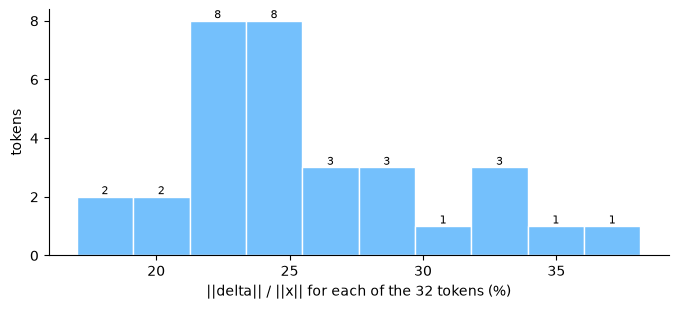

In [33]:
# How much does the block change each token? Sizes of x, delta and x_out, token by token.
import torch.nn.functional as F

share = (delta.norm(dim=-1) / x.norm(dim=-1)).flatten().detach()
cosine = F.cosine_similarity(x_out, x, dim=-1).flatten().detach()
print(f'std of x {x.std():.2f}, of delta {delta.std():.2f}, of x_out {x_out.std():.2f}')
print(f'||delta|| / ||x|| per token: from {100 * share.min():.2f}% to {100 * share.max():.2f}%, '
      f'mean {100 * share.mean():.2f}%')
print(f'cosine(x_out, x) per token: from {cosine.min():.3f} to {cosine.max():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
counts, _, bars = ax.hist(100 * share, bins=10, color='#74c0fc', edgecolor='white')
ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=8)
ax.set_xlabel('||delta|| / ||x|| for each of the 32 tokens (%)')
ax.set_ylabel('tokens')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The global standard deviations are 0.97 for the input, 0.24 for the branch and 1.00 for their sum. Per-token correction ratios range from 17.02% to 38.15%, averaging 25.39%.

Cosines from 0.941 to 0.986 show close directional alignment in this example. They do not measure how much information could be recovered from the output.

My small-correction hypothesis fits this input scale. I next keep the weights and token directions fixed while multiplying the input by different positive factors.

x * 0.1: std of delta 0.238, mean ||delta|| / ||x|| 253.75%
x * 1: std of delta 0.238, mean ||delta|| / ||x|| 25.39%
x * 10: std of delta 0.238, mean ||delta|| / ||x|| 2.54%
x * 100: std of delta 0.238, mean ||delta|| / ||x|| 0.25%


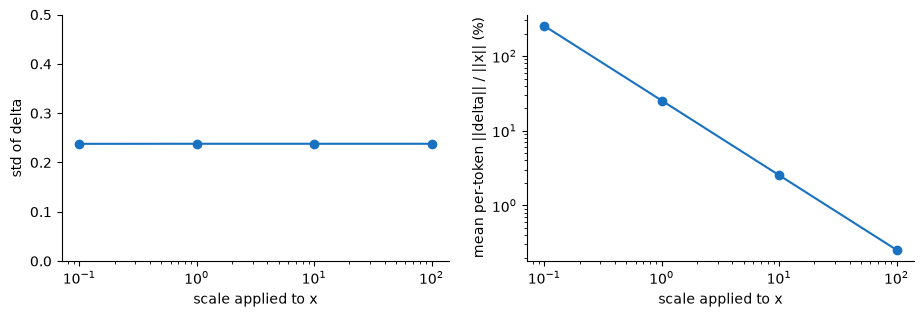

In [34]:
# Does the branch follow the scale of x? The same tokens scaled from 0.1 to 100.
SCALES = [0.1, 1, 10, 100]
delta_stds, shares = [], []
for s in SCALES:
    scaled_delta = ffwd(layer_norm(x * s))
    delta_stds.append(scaled_delta.std().item())
    shares.append(100 * (scaled_delta.norm(dim=-1) / (x * s).norm(dim=-1)).mean().item())
    print(f'x * {s:g}: std of delta {delta_stds[-1]:.3f}, mean ||delta|| / ||x|| {shares[-1]:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, values, label in ((axes[0], delta_stds, 'std of delta'),
                          (axes[1], shares, 'mean per-token ||delta|| / ||x|| (%)')):
    ax.plot(SCALES, values, marker='o', color='#1971c2')
    ax.set_xscale('log')
    ax.set_xlabel('scale applied to x')
    ax.set_ylabel(label)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylim(0, 0.5)
axes[1].set_yscale('log')
plt.show()

Across the four tested scales, the branch standard deviation rounds to 0.238. The mean correction ratio changes from 253.75% at scale 0.1 to 0.25% at scale 100.

At the smallest scale, the correction is larger than the input, so my initial small-correction assumption cannot hold generally. With fixed weights, normalisation makes the branch approximately insensitive to these positive scale changes when epsilon is small enough.

This says nothing about branch scales after parameter updates. I next examine the local derivative because output magnitudes alone do not determine gradient behaviour.

block, v + ffwd(layer_norm(v)): diagonal mean 1.0006, singular values from 0.65 to 1.49
branch alone, ffwd(layer_norm(v)): diagonal mean 0.0006, singular values from 0.00 to 0.60


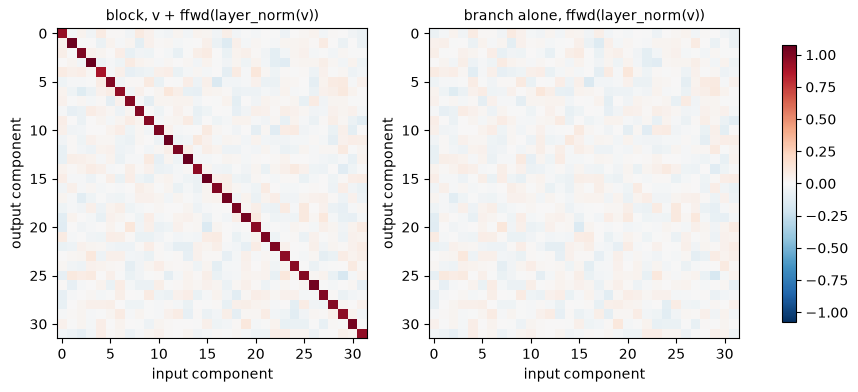

In [35]:
# How does a gradient cross the block? Jacobian of one token, through the block and the branch.
token = x[0, 0]
jacobians = {
    'block, v + ffwd(layer_norm(v))': torch.autograd.functional.jacobian(
        lambda v: v + ffwd(layer_norm(v)), token),
    'branch alone, ffwd(layer_norm(v))': torch.autograd.functional.jacobian(
        lambda v: ffwd(layer_norm(v)), token),
}
for name, jacobian in jacobians.items():
    singular = torch.linalg.svdvals(jacobian)
    print(f'{name}: diagonal mean {jacobian.diagonal().mean():.4f}, '
          f'singular values from {singular.min():.2f} to {singular.max():.2f}')

limit = max(jacobian.abs().max().item() for jacobian in jacobians.values())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, jacobian) in zip(axes, jacobians.items()):
    image = ax.imshow(jacobian, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('input component')
    ax.set_ylabel('output component')
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

The Jacobian records how a small input change affects each output component. Here the block's singular values range from 0.65 to 1.49, while the branch's range rounds to 0.00 through 0.60.

A value printed as 0.00 does not establish exact zero. Mean subtraction removes a shared-shift direction mathematically, while epsilon means scale invariance is only approximate.

The lower value 0.65 describes this local Jacobian, not a guarantee for every block. I check the identity contribution explicitly before interpreting the gradient path.

In [36]:
# Separate the identity and branch contributions for a fixed output-gradient direction.
demo_grad_block = jacobians['block, v + ffwd(layer_norm(v))'].detach().clone()
demo_grad_branch = jacobians['branch alone, ffwd(layer_norm(v))'].detach().clone()
demo_grad_identity = torch.eye(n_embd, dtype=token.dtype, device=token.device)
demo_grad_probe = torch.zeros_like(token)
demo_grad_probe[0] = 1
demo_grad_expected = demo_grad_probe + demo_grad_branch.T @ demo_grad_probe
demo_grad_token = token.detach().clone().requires_grad_()
demo_grad_output = demo_grad_token + ffwd(layer_norm(demo_grad_token))
demo_grad_actual, = torch.autograd.grad(demo_grad_output, demo_grad_token, demo_grad_probe)
assert torch.allclose(demo_grad_block, demo_grad_identity + demo_grad_branch, atol=1e-6)
assert torch.allclose(demo_grad_block.T @ demo_grad_probe, demo_grad_expected, atol=1e-6)
assert torch.allclose(demo_grad_actual, demo_grad_expected, atol=1e-6)

print(f'J_block - (I + J_branch), largest gap '
      f'{(demo_grad_block - demo_grad_identity - demo_grad_branch).abs().max().item():.1e}')
print(f'identity contribution, first four components {demo_grad_probe[:4].tolist()}')
print(f'branch contribution, first four components '
      f'{[round(v, 6) for v in (demo_grad_branch.T @ demo_grad_probe)[:4].tolist()]}')
print(f'sum, first four components {[round(v, 6) for v in demo_grad_expected[:4].tolist()]}')
print(f'autograd agreement, largest gap {(demo_grad_actual - demo_grad_expected).abs().max():.1e}')

J_block - (I + J_branch), largest gap 5.6e-08
identity contribution, first four components [1.0, 0.0, 0.0, 0.0]
branch contribution, first four components [-0.06426, -0.019269, 0.033869, -0.040762]
sum, first four components [0.93574, -0.019269, 0.033869, -0.040762]
autograd agreement, largest gap 0.0e+00


For this probe, the backward gradient is the incoming direction plus the branch contribution. Its first component falls from 1.0 to 0.93574 because the branch contributes -0.06426.

The contributions can reinforce or cancel each other, so the identity term does not guarantee a minimum total gradient. `autograd.grad` calculates input sensitivity here without accumulating parameter gradients or applying an optimiser update.

I next reuse prefixes of one stack at different depths with a fixed probe `g` and scalar `(z * g).sum()`. Each depth gets a fresh input leaf, and accumulated parameter gradients are never used to update weights.

depth 1: std of the stream 1.00, gradient at x / ||g|| 1.03, cosine to x 0.97
depth 4: std of the stream 1.10, gradient at x / ||g|| 1.17, cosine to x 0.90
depth 8: std of the stream 1.19, gradient at x / ||g|| 1.27, cosine to x 0.83
depth 16: std of the stream 1.39, gradient at x / ||g|| 1.52, cosine to x 0.71
depth 32: std of the stream 1.67, gradient at x / ||g|| 1.77, cosine to x 0.60


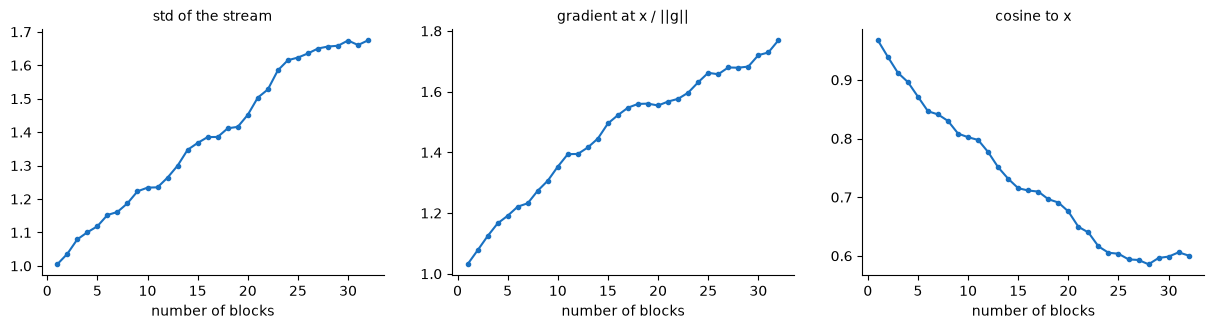

In [37]:
# What happens across many blocks? 32 pre-norm blocks with fresh weights, depth by depth.
torch.manual_seed(RANDOM_STATE)
blocks = [(nn.LayerNorm(n_embd), FeedForward(n_embd)) for _ in range(32)]
g = torch.randn(B, T, n_embd)  # a fixed direction for the gradient, loss = (z * g).sum()
history = {'std of the stream': [], 'gradient at x / ||g||': [], 'cosine to x': []}
for depth in range(1, 33):
    start = x.detach().clone().requires_grad_()
    z = start
    for norm_layer, network in blocks[:depth]:
        z = z + network(norm_layer(z))
    (z * g).sum().backward()
    history['std of the stream'].append(z.std().item())
    history['gradient at x / ||g||'].append((start.grad.norm() / g.norm()).item())
    history['cosine to x'].append(F.cosine_similarity(z.flatten(), x.flatten(), dim=0).item())
for depth in (1, 4, 8, 16, 32):
    print(f'depth {depth}: '
          + ', '.join(f'{name} {values[depth - 1]:.2f}' for name, values in history.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, (name, values) in zip(axes, history.items()):
    ax.plot(range(1, 33), values, marker='o', markersize=3, color='#1971c2')
    ax.set_xlabel('number of blocks')
    ax.set_title(name, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

At depths one and 32, the stream standard deviation is 1.00 and 1.67, while the input-gradient norm ratio is 1.03 and 1.77. The cosine to the original input falls from 0.97 to 0.60.

These endpoints describe one fixed probe through shared prefixes of the same randomly initialised stack. They do not establish behaviour for every gradient direction or a language-model loss.

The positive cosine indicates directional alignment, not a measured amount of retained information. I will reuse the same blocks, input and probe without the addition to isolate its effect.

> *My conclusion:*
>
> The residual operation preserves shape and adds the input directly to the branch output. Its mean correction ratio is 25.39% at the original scale, but rises to 253.75% when the input is multiplied by 0.1.
>
> I therefore restrict my small-correction hypothesis to the tested original input scale. Pre-normalisation does not guarantee that a branch remains small relative to its residual stream.
>
> The derivative contains an identity contribution, which can combine constructively or destructively with the branch derivative. The stack measures this combination for one probe without training or establishing a universal gradient bound.

## 5. Test variants

I first replace ReLU with GELU using identical weights and inputs. I then compare hidden widths and parameter counts, before removing the residual addition from the original block and stack.

The width comparison requires differently shaped weights and uses different initial draws. I can compare its dimensions and counts exactly, but cannot attribute every numerical difference to width alone.

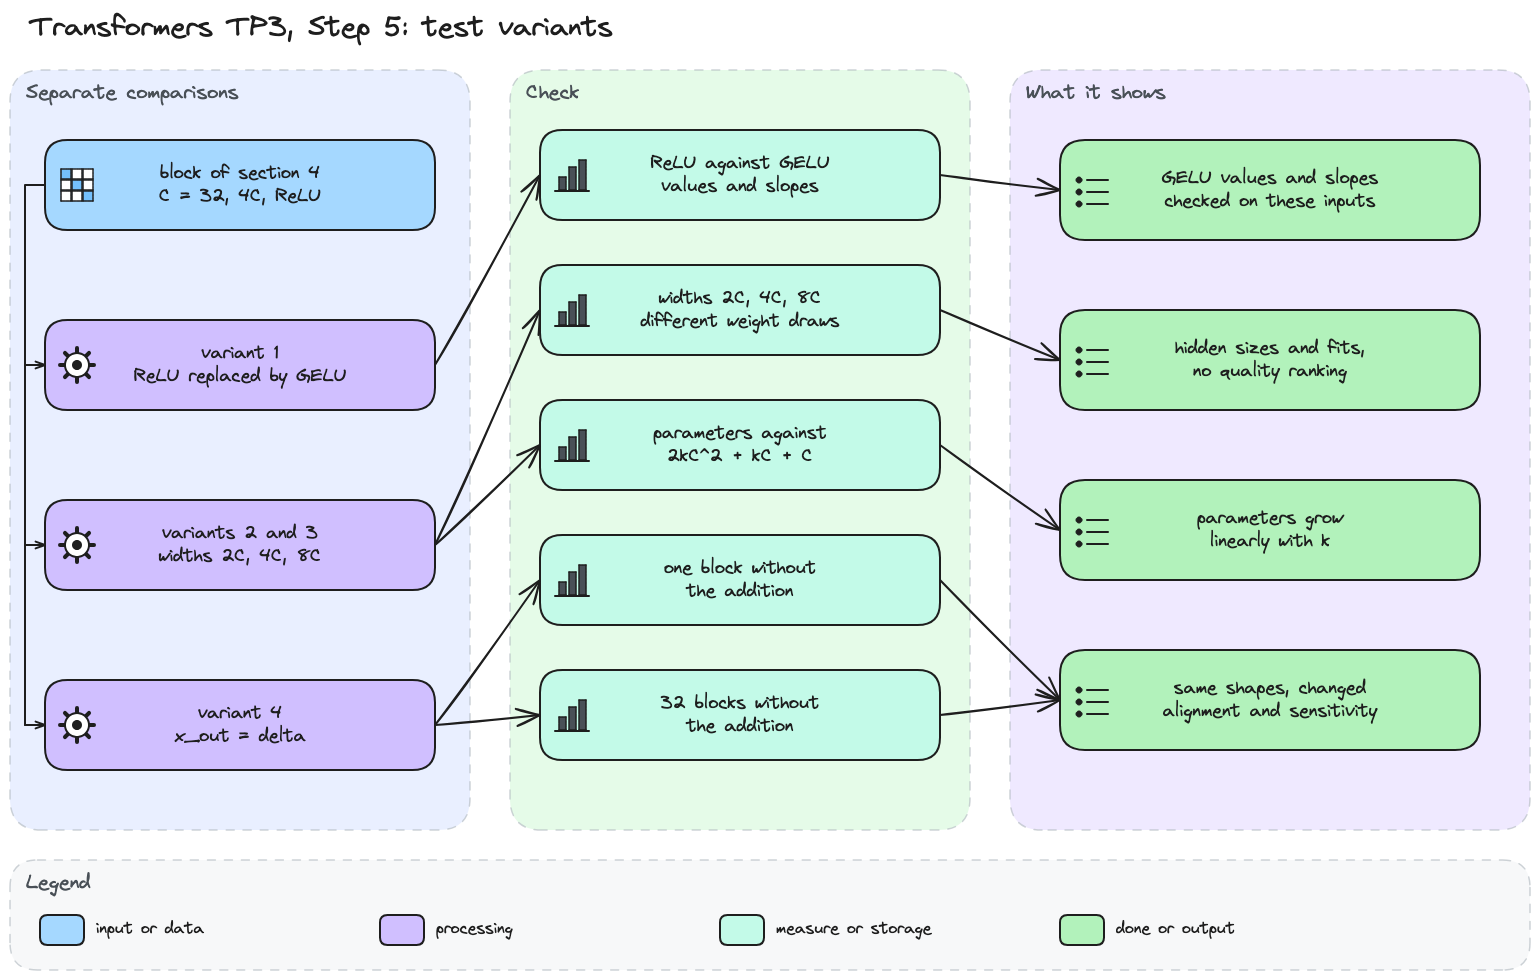

In [38]:
# Step 5 diagram: the four variants of the block, and what each one shows.
display(Image(filename='diagrams/transformers/tp3_step5.png', width=900))

In [39]:
# Variant 1: GELU in place of ReLU, with the same weights as the block of section 4.
import copy

gelu_ffwd = copy.deepcopy(ffwd)
gelu_ffwd.net[1] = nn.GELU()
delta_gelu = gelu_ffwd(layer_norm(x))
print(f'delta with GELU: {tuple(delta_gelu.shape)}, std {delta_gelu.std():.3f} '
      f'against {delta.std():.3f} with ReLU')
print(f'Largest gap with the ReLU delta: {(delta_gelu - delta).abs().max():.2f}')

delta with GELU: (4, 8, 32), std 0.208 against 0.238 with ReLU
Largest gap with the ReLU delta: 0.22


With identical weights and inputs, GELU gives the same output shape and a standard deviation of 0.208, compared with 0.238 for ReLU. The maximum output difference is 0.22.

This isolates the effect of the activation in the existing block. I next inspect values and derivatives to understand that difference without interpreting it as a performance improvement.

ReLU on the hidden values: zeros 49.80%, negatives 0.00%, zero slopes 49.80%, minimum 0.000
GELU on the hidden values: zeros 0.00%, negatives 49.80%, zero slopes 0.00%, minimum -0.170


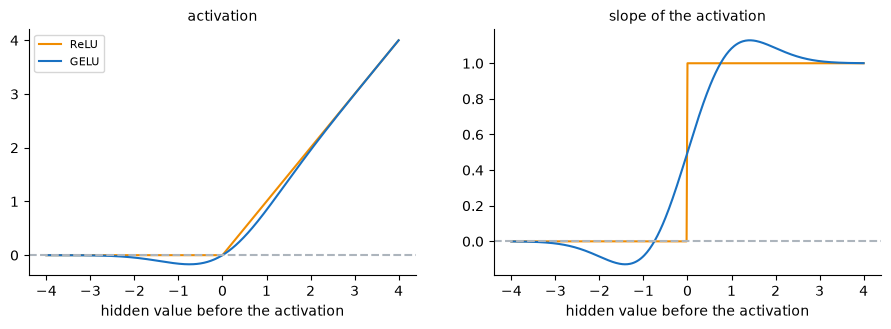

In [40]:
# Where do ReLU and GELU differ? Their values and slopes, then their effect on the hidden values.
grid = torch.linspace(-4, 4, 401, requires_grad=True)
hidden_pre = ffwd.net[0](layer_norm(x)).detach()  # the 128 hidden values of each token
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for activation, color in ((nn.ReLU(), '#f08c00'), (nn.GELU(), '#1971c2')):
    name = activation.__class__.__name__
    values = activation(grid)
    slope, = torch.autograd.grad(values.sum(), grid)
    axes[0].plot(grid.detach(), values.detach(), color=color, label=name)
    axes[1].plot(grid.detach(), slope, color=color, label=name)
    pre = hidden_pre.clone().requires_grad_()
    out = activation(pre)
    pre_slope, = torch.autograd.grad(out.sum(), pre)
    print(f'{name} on the hidden values: zeros {100 * (out == 0).float().mean():.2f}%, '
          f'negatives {100 * (out < 0).float().mean():.2f}%, '
          f'zero slopes {100 * (pre_slope == 0).float().mean():.2f}%, minimum {out.min():.3f}')
for ax, title in ((axes[0], 'activation'), (axes[1], 'slope of the activation')):
    ax.axhline(0, linestyle='--', color='#adb5bd')
    ax.set_xlabel('hidden value before the activation')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

On these hidden values, ReLU produces 49.80% zeros with zero local slopes. GELU retains negative outputs, reaching -0.170, and none of the sampled slopes is exactly zero.

The curves approach similar behaviour away from the transition region, but need not be exactly equal. GELU also has a region of negative slope, so a smooth activation does not simply pass every gradient unchanged.

The absence of zero GELU slopes here does not guarantee useful gradients on other inputs. I have measured local sensitivities, without measuring training success.

2C: hidden (4, 8, 64), output (4, 8, 32), delta std 0.255, positive 48.97%, affine-fit residual / target variance 14.71%
4C: hidden (4, 8, 128), output (4, 8, 32), delta std 0.230, positive 51.39%, affine-fit residual / target variance 18.04%
8C: hidden (4, 8, 256), output (4, 8, 32), delta std 0.242, positive 51.18%, affine-fit residual / target variance 17.11%


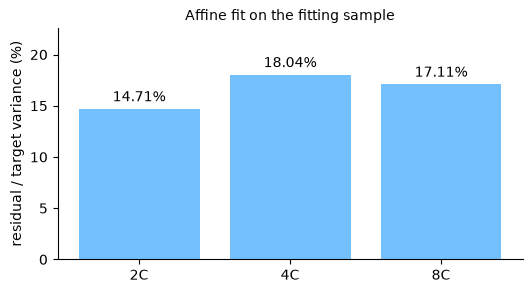

In [41]:
# Variant 2: hidden widths 2C, 4C and 8C. What changes besides the hidden size?
torch.manual_seed(RANDOM_STATE)
FACTORS = [2, 4, 8]
widths = {k: nn.Sequential(nn.Linear(n_embd, k * n_embd), nn.ReLU(), nn.Linear(k * n_embd, n_embd))
          for k in FACTORS}
sample = torch.randn(2000, n_embd)
design = torch.cat([sample, torch.ones(2000, 1)], dim=1)  # a column of ones for the bias
unexplained = []
for k, net in widths.items():
    hidden_k = net[1](net[0](layer_norm(x)))
    out_k = net(layer_norm(x))
    target = net(sample).detach()
    fit = design @ torch.linalg.lstsq(design, target).solution
    unexplained.append(100 * ((fit - target).var() / target.var()).item())
    print(f'{k}C: hidden {tuple(hidden_k.shape)}, output {tuple(out_k.shape)}, '
          f'delta std {out_k.std():.3f}, positive {100 * (hidden_k > 0).float().mean():.2f}%, '
          f'affine-fit residual / target variance {unexplained[-1]:.2f}%')

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar([f'{k}C' for k in FACTORS], unexplained, color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in unexplained], padding=3)
ax.set_ylabel('residual / target variance (%)')
ax.set_title('Affine fit on the fitting sample', fontsize=10)
ax.set_ylim(0, max(unexplained) * 1.25)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Widths 2C, 4C and 8C give hidden sizes 64, 128 and 256, while every output stays (4, 8, 32). Output standard deviations range from 0.230 to 0.255 and positive shares from 48.97% to 51.39%.

The affine-fit residual-to-target variance ratios are 14.71%, 18.04% and 17.11% on the common fitting sample. The networks use different initial weights, so these values cannot isolate a causal effect of width or rank model quality.

Parameter counts provide a simpler comparison because the architecture determines them directly. I calculate them next, including the biases.

2C: 4,192 parameters, 2kC² + kC + C = 4,192
4C: 8,352 parameters, 2kC² + kC + C = 8,352
8C: 16,672 parameters, 2kC² + kC + C = 16,672
LayerNorm(32): 64, TP2 head: 1,536 parameters


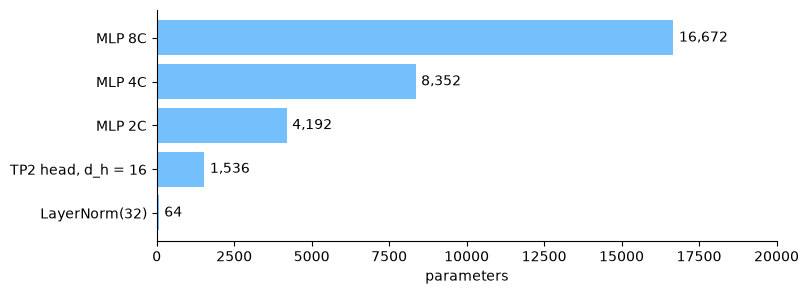

In [42]:
# Variant 3: parameters of each width against 2kC² + kC + C, next to the other pieces I built.
counts = {f'MLP {k}C': sum(p.numel() for p in net.parameters()) for k, net in widths.items()}
for k in FACTORS:
    formula = 2 * k * n_embd**2 + k * n_embd + n_embd
    print(f'{k}C: {counts[f"MLP {k}C"]:,} parameters, 2kC² + kC + C = {formula:,}')
head = [nn.Linear(n_embd, 16, bias=False) for _ in range(3)]  # key, query, value of my TP2 head
counts = {'LayerNorm(32)': sum(p.numel() for p in layer_norm.parameters()),
          'TP2 head, d_h = 16': sum(p.numel() for layer in head for p in layer.parameters()),
          **counts}
print(f'LayerNorm(32): {counts["LayerNorm(32)"]:,}, '
      f'TP2 head: {counts["TP2 head, d_h = 16"]:,} parameters')

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(list(counts), list(counts.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:,}' for value in counts.values()], padding=4)
ax.set_xlim(0, max(counts.values()) * 1.2)
ax.set_xlabel('parameters')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The measured counts match 2kC² + kC + C, giving 4,192, 8,352 and 16,672 parameters. For C = 32, each extra unit of k adds 2,080 parameters, confirming the count part of my last hypothesis.

The 4C network has 8,352 parameters, compared with 1,536 for the TP2 head and 64 for LayerNorm. These are counts for selected components, not measurements of runtime or a complete Transformer block.

I now return to the original block and remove only its residual addition. Using the same branch output prevents a new random initialisation from obscuring that comparison.

In [43]:
# Variant 4: the block without its residual addition. Do the shapes reveal it?
x_out_plain = delta  # ffwd(layer_norm(x)), without + x
print(f'x: {tuple(x.shape)}, delta: {tuple(delta.shape)}, '
      f'x_out without the addition: {tuple(x_out_plain.shape)}')
for name, output in (('with the addition', x_out), ('without the addition', x_out_plain)):
    print(f'{name}: mean cosine to x {F.cosine_similarity(output, x, dim=-1).mean():.3f}')

x: (4, 8, 32), delta: (4, 8, 32), x_out without the addition: (4, 8, 32)
with the addition: mean cosine to x 0.969
without the addition: mean cosine to x 0.023


Removing the addition preserves shape (4, 8, 32), so the shape part of my last hypothesis holds. Mean cosine to the input changes from 0.969 to 0.023.

The branch output is nearly orthogonal to the input on average. That does not establish that input information has disappeared or could not be decoded.

I next remove the addition from the same stack used in section 4. The input, block weights, depth prefixes and gradient probe remain fixed.

depth 1: std of the stream 0.25, gradient at x / ||g|| 0.24, cosine to x 0.01
depth 4: std of the stream 0.23, gradient at x / ||g|| 0.20, cosine to x -0.00
depth 8: std of the stream 0.22, gradient at x / ||g|| 0.30, cosine to x 0.11
depth 16: std of the stream 0.24, gradient at x / ||g|| 0.26, cosine to x -0.00
depth 32: std of the stream 0.22, gradient at x / ||g|| 0.30, cosine to x 0.02


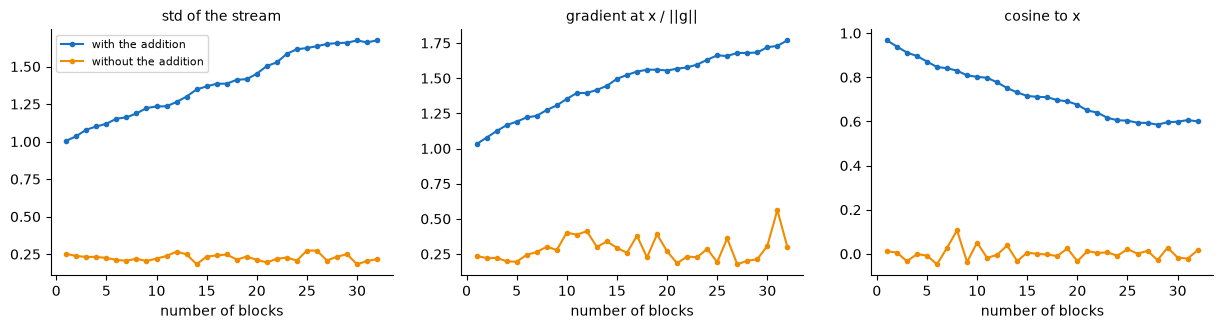

In [44]:
# What changes without the addition? The 32 blocks of section 4, rerun without it.
history_plain = {name: [] for name in history}
for depth in range(1, 33):
    start = x.detach().clone().requires_grad_()
    z = start
    for norm_layer, network in blocks[:depth]:
        z = network(norm_layer(z))  # no residual addition
    (z * g).sum().backward()
    history_plain['std of the stream'].append(z.std().item())
    history_plain['gradient at x / ||g||'].append((start.grad.norm() / g.norm()).item())
    history_plain['cosine to x'].append(F.cosine_similarity(z.flatten(), x.flatten(), dim=0).item())
for depth in (1, 4, 8, 16, 32):
    print(f'depth {depth}: '
          + ', '.join(f'{name} {values[depth - 1]:.2f}' for name, values in history_plain.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, name in zip(axes, history):
    ax.plot(range(1, 33), history[name], marker='o', markersize=3, color='#1971c2',
            label='with the addition')
    ax.plot(range(1, 33), history_plain[name], marker='o', markersize=3, color='#f08c00',
            label='without the addition')
    ax.set_xlabel('number of blocks')
    ax.set_title(name, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

At the five printed depths, the stream standard deviation is between 0.22 and 0.25 without the addition. Cosines are near zero, while input-gradient norm ratios range from 0.20 to 0.30.

At those same checkpoints, residual-stack gradient ratios range from 1.03 to 1.77. The comparison isolates the addition for this stack and probe, while the full curves show the intervening depths.

I can conclude that the addition changes alignment and sensitivity in this experiment. These measurements do not establish information loss, general gradient bounds or successful optimisation.

> *My conclusion:*
>
> Shape preservation holds for every variant, but the outputs and local derivatives differ. The activation and residual comparisons reuse weights, while width changes also introduce different weight draws.
>
> My results for the four variants of this step:
>
> 1. GELU changes the original branch output by up to 0.22. Its sampled negative outputs and slopes differ from ReLU without establishing a training advantage.
> 2. Widths 2C, 4C and 8C give hidden sizes 64, 128 and 256. Their numerical differences do not rank useful capacity.
> 3. Parameter counts are 4,192, 8,352 and 16,672, matching 2kC² + kC + C.
> 4. Removing the residual preserves shape and changes mean cosine from 0.969 to 0.023. Its stack has gradient ratios from 0.20 to 0.30 at the printed checkpoints.

## Summary

I return to my hypotheses with their limits attached. The first needs correction, and the small-residual hypothesis depends on input scale.

I finish by checking shapes and token dependencies across the components together. The parameter comparison then shows what was actually counted before I consider assembling a complete model.

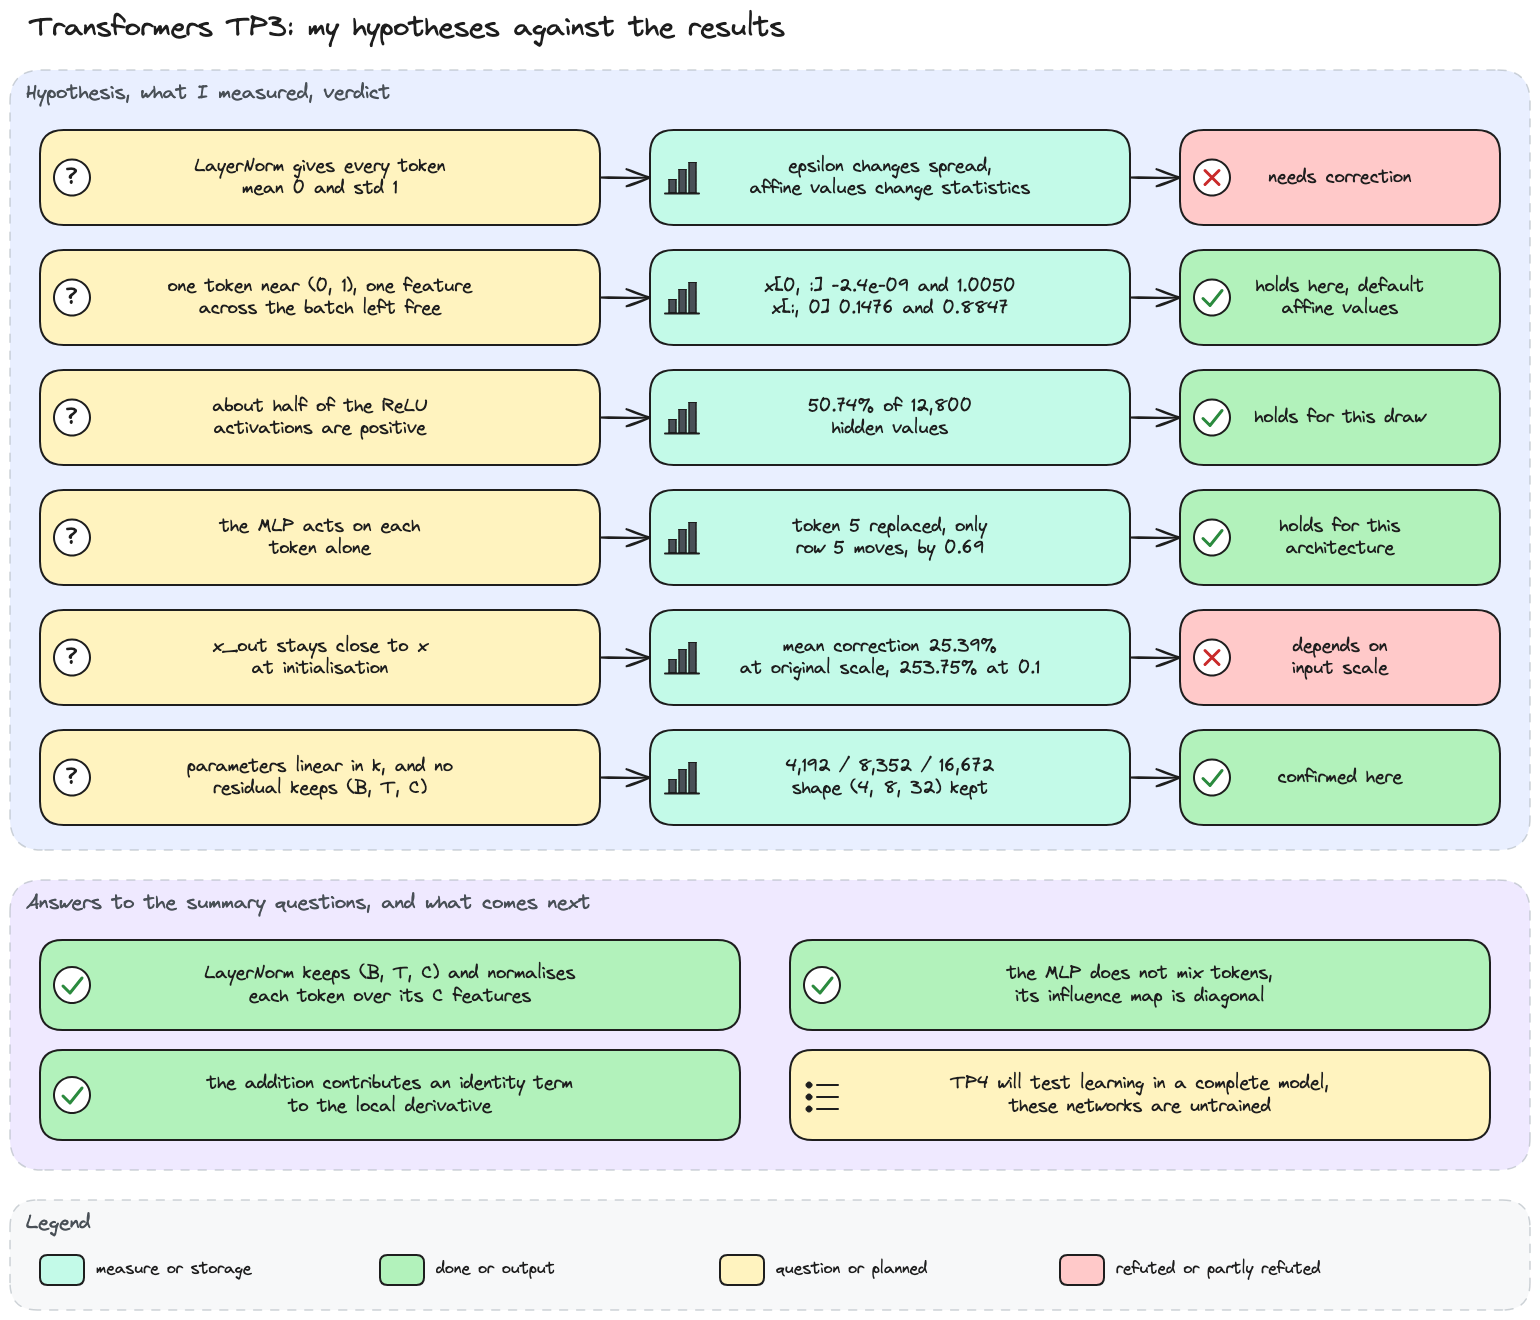

In [45]:
# Summary diagram: my hypotheses, what I measured, my verdicts, and the summary answers.
display(Image(filename='diagrams/transformers/tp3_summary.png', width=900))

In [46]:
# Which dimension does each piece keep? Input and output shapes on two sizes of tokens.
torch.manual_seed(RANDOM_STATE)
for shape in ((4, 8, 32), (32, 100)):
    size = shape[-1]
    tokens_in = torch.randn(shape)
    pieces = {'my LayerNorm1d': LayerNorm1d(size), 'nn.LayerNorm': nn.LayerNorm(size),
              'FeedForward': FeedForward(size)}
    pieces['block'] = lambda v: v + pieces['FeedForward'](pieces['nn.LayerNorm'](v))
    print(f'input {shape}, statistics of LayerNorm over the last dimension, of size {size}')
    for name, piece in pieces.items():
        print(f'    {name}: output {tuple(piece(tokens_in).shape)}')

input (4, 8, 32), statistics of LayerNorm over the last dimension, of size 32
    my LayerNorm1d: output (4, 8, 32)
    nn.LayerNorm: output (4, 8, 32)
    FeedForward: output (4, 8, 32)
    block: output (4, 8, 32)
input (32, 100), statistics of LayerNorm over the last dimension, of size 100
    my LayerNorm1d: output (32, 100)
    nn.LayerNorm: output (32, 100)
    FeedForward: output (32, 100)
    block: output (32, 100)


Every tested component preserves both input shapes, (4, 8, 32) and (32, 100). LayerNorm takes statistics over the last dimension while the other axes index separate tokens.

To distinguish shape preservation from token independence, I inspect Jacobians between positions. I include TP2's causal average as a reference that deliberately mixes visible positions.

LayerNorm: largest influence on another token 0.00, from a later token 0.00
MLP: largest influence on another token 0.00, from a later token 0.00
block: largest influence on another token 0.00, from a later token 0.00
causal average of TP2: largest influence on another token 2.83, from a later token 0.00


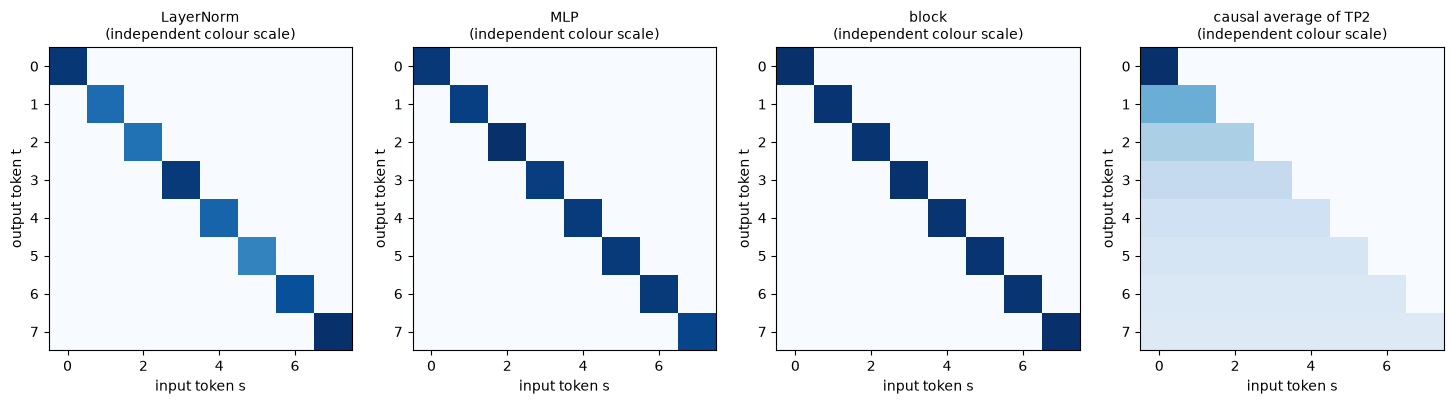

In [47]:
# Does any piece mix positions? How much input token s moves output token t, in sequence 0.
causal_average = torch.tril(torch.ones(T, T))
causal_average = causal_average / causal_average.sum(1, keepdim=True)
pieces = {'LayerNorm': layer_norm, 'MLP': ffwd, 'block': lambda v: v + ffwd(layer_norm(v)),
          'causal average of TP2': lambda v: causal_average @ v}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, piece) in zip(axes, pieces.items()):
    jacobian = torch.autograd.functional.jacobian(piece, x[0])  # (T, C, T, C)
    influence = jacobian.norm(dim=(1, 3))  # (T, T): output token t, input token s
    others = influence - torch.diag(torch.diag(influence))
    print(f'{name}: largest influence on another token {others.max():.2f}, '
          f'from a later token {influence.triu(1).max():.2f}')
    assert torch.count_nonzero(influence.triu(1)) == 0
    if name != 'causal average of TP2':
        assert torch.count_nonzero(others) == 0
    ax.imshow(influence, cmap='Blues')
    ax.set_title(name + '\n(independent colour scale)', fontsize=10)
    ax.set_xlabel('input token s')
    ax.set_ylabel('output token t')
plt.show()

The influence maps for LayerNorm, the MLP and their residual block are diagonal, with zero influence between different tokens. The causal average reaches 2.83 off the diagonal and zero above it.

These results agree with the operations' structure. The average mixes earlier positions, whereas the components built here transform each position independently.

Each panel uses its own colour scale, so I compare the dependency patterns rather than colour intensity across panels. None of these operations uses a future token.

LayerNorm(32): 64 parameters, 0.64% of 9,952
MLP 4C: 8,352 parameters, 83.92% of 9,952
TP2 head, d_h = 16: 1,536 parameters, 15.43% of 9,952


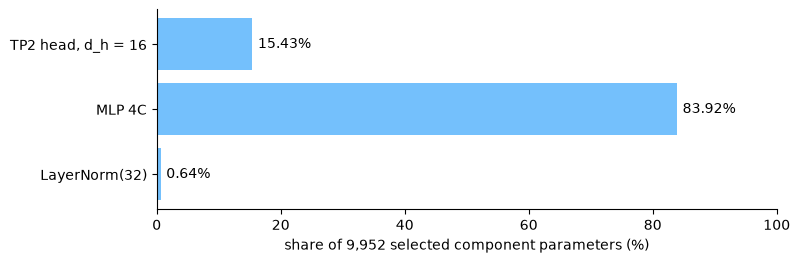

In [48]:
# Compare selected component counts, excluding the rest of a complete Transformer block.
budget = {name: counts[name] for name in ('LayerNorm(32)', 'MLP 4C', 'TP2 head, d_h = 16')}
total = sum(budget.values())
for name, count in budget.items():
    print(f'{name}: {count:,} parameters, {100 * count / total:.2f}% of {total:,}')

fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(list(budget), [100 * count / total for count in budget.values()], color='#74c0fc')
ax.bar_label(bars, labels=[f'{100 * count / total:.2f}%' for count in budget.values()], padding=4)
ax.set_xlim(0, 100)
ax.set_xlabel(f'share of {total:,} selected component parameters (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The selected components total 9,952 parameters, with 83.92% in the MLP, 15.43% in the TP2 head and 0.64% in LayerNorm. The percentages describe this selection only.

It is not a complete executable Transformer block because the head returns 16 channels while the residual stream has 32. The count also omits a compatible attention output projection, other normalisation layers and embeddings.

I therefore use this chart to compare parameter counts of the pieces I built. It does not establish total model cost or whether attention is cheaper to compute.

> *My conclusion:*
>
> My initial hypotheses led to useful checks, including corrections to what I expected.
>
> - LayerNorm does not always give standard deviation one. Epsilon affects the denominator, and affine parameters can change the resulting mean and spread.
> - The predicted row and feature distinction holds with the default affine values. Reporting standard deviation also requires specifying the variance convention.
> - The original ReLU network has 50.74% positive activations. That supports the approximate-half prediction for this draw, with no guarantee for other inputs.
> - The MLP operates on each token independently, as both its structure and the replacement test indicate.
> - The residual correction averages 25.39% of the input norm at the original scale. The 253.75% result at scale 0.1 qualifies my small-correction assumption.
> - Parameter counts grow by 2,080 per unit of k here, and removing the residual preserves shape.
>
> My answers to the three summary questions of TP3:
>
> 1. LayerNorm preserves (B, T, C) and normalises over C for each token independently.
> 2. The MLP does not mix positions. Its projections and activation act within each token.
> 3. The residual adds the input to the branch and contributes an identity term to the derivative. Total sensitivity still depends on the branch and the evaluation point.
>
> I now check definitions and reporting conventions before interpreting a rounded result. I also distinguish comparisons that reuse weights from those that introduce new initialisations.
>
> A matching shape, a small numerical gap and a favourable gradient probe answer different questions. None alone demonstrates learning, so TP4 will need an actual training objective and evaluation.
>
> These conclusions use the existing fixed seeds, synthetic inputs and untrained networks. I have not measured language quality or repeated-run uncertainty here.